In [ ]:
# GridDefense | Step 1: Install & Import

!pip install pypower -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypower.api import case14, runpf, ppoption

# Reproducibility - same random results every run
np.random.seed(42)

print("PyPower installed")
print("All libraries imported")

# Load IEEE 14-bus
ppc = case14()

print(f"\n IEEE 14-Bus System Loaded:")
print(f"  Buses     : {ppc['bus'].shape[0]}")
print(f"  Branches  : {ppc['branch'].shape[0]}")
print(f"  Generators: {ppc['gen'].shape[0]}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.6/347.6 kB 4.9 MB/s eta 0:00:00
PyPower installed
All libraries imported

 IEEE 14-Bus System Loaded:
  Buses     : 14
  Branches  : 20
  Generators: 5


In [ ]:
# GridDefense | Step 2: Explore the IEEE 14-bus Structure
# Understanding what data PYPOWER gives us


print("=" * 55)
print("BUS DATA — first 5 buses")
print("=" * 55)
print(f"Bus matrix shape: {ppc['bus'].shape}")
print(f"Columns: Bus No | Type | Pd | Qd | Gs | Bs | Area | Vm | Va | BaseKV | Zone | Vmax | Vmin")
print()
print(ppc['bus'][:5, :])

print("\n" + "=" * 55)
print("BRANCH DATA — first 5 branches")
print("=" * 55)
print(f"Branch matrix shape: {ppc['branch'].shape}")
print(f"Columns: From | To | R | X | B | RateA | RateB | RateC | ...")
print()
print(ppc['branch'][:5, :5])  # just first 5 columns

print("\n" + "=" * 55)
print("WHAT WE CARE ABOUT:")
print("=" * 55)
print("From bus data:")
print(f"  Vm (voltage magnitude) → column 7")
print(f"  Va (voltage angle)     → column 8")
print(f"  Pd (active power load) → column 2")
print(f"  Qd (reactive power)    → column 3")
print("\nFrom branch data:")
print(f"  From bus → column 0")
print(f"  To bus   → column 1")
print(f"  R (resistance)  → column 2")
print(f"  X (reactance)   → column 3")
print("\nThese are the measurements our PMU sensors would record.")
print("These are what an attacker would manipulate in FDIA.")

BUS DATA — first 5 buses
Bus matrix shape: (14, 13)
Columns: Bus No | Type | Pd | Qd | Gs | Bs | Area | Vm | Va | BaseKV | Zone | Vmax | Vmin

[[  1.      3.      0.      0.      0.      0.      1.      1.06    0.
    0.      1.      1.06    0.94 ]
 [  2.      2.     21.7    12.7     0.      0.      1.      1.045  -4.98
    0.      1.      1.06    0.94 ]
 [  3.      2.     94.2    19.      0.      0.      1.      1.01  -12.72
    0.      1.      1.06    0.94 ]
 [  4.      1.     47.8    -3.9     0.      0.      1.      1.019 -10.33
    0.      1.      1.06    0.94 ]
 [  5.      1.      7.6     1.6     0.      0.      1.      1.02   -8.78
    0.      1.      1.06    0.94 ]]

BRANCH DATA — first 5 branches
Branch matrix shape: (20, 13)
Columns: From | To | R | X | B | RateA | RateB | RateC | ...

[[1.      2.      0.01938 0.05917 0.0528 ]
 [1.      5.      0.05403 0.22304 0.0492 ]
 [2.      3.      0.04699 0.19797 0.0438 ]
 [2.      4.      0.05811 0.17632 0.034  ]
 [2.      5.      0.05

In [ ]:
# GridDefense | Step 3: Run Power Flow & Extract Measurements
# This is what ONE timestep of PMU data looks like


# Set PYPOWER options - suppress output
opt = ppoption(VERBOSE=0, OUT_ALL=0)

# Run AC power flow
result = runpf(ppc, opt)

# Extract the solved case
solved = result[0]
success = result[1]

print(f"Power flow converged: {bool(success)}")
print()

# Extract measurements from all 14 buses
bus_data = solved['bus']

# Our 4 key measurements per bus
Vm = bus_data[:, 7]   # Voltage magnitude (pu)
Va = bus_data[:, 8]   # Voltage angle (degrees)
Pd = bus_data[:, 2]   # Active power load (MW)
Qd = bus_data[:, 3]   # Reactive power load (MVAr)

print("=" * 45)
print("PMU Measurements — All 14 Buses")
print("=" * 45)
print(f"{'Bus':>4} {'Vm(pu)':>8} {'Va(deg)':>8} {'Pd(MW)':>8} {'Qd(MVAr)':>10}")
print("-" * 45)
for i in range(14):
    print(f"{i+1:>4} {Vm[i]:>8.4f} {Va[i]:>8.3f} {Pd[i]:>8.2f} {Qd[i]:>10.2f}")

print()
print(f"Total active load:    {Pd.sum():.2f} MW")
print(f"Total reactive load:  {Qd.sum():.2f} MVAr")
print()
print("This is what ONE timestep of normal PMU data looks like.")
print("We will generate 5000 of these with varying loads.")

Power flow converged: True

PMU Measurements — All 14 Buses
 Bus   Vm(pu)  Va(deg)   Pd(MW)   Qd(MVAr)
---------------------------------------------
   1   1.0600    0.000     0.00       0.00
   2   1.0450   -4.983    21.70      12.70
   3   1.0100  -12.725    94.20      19.00
   4   1.0177  -10.313    47.80      -3.90
   5   1.0195   -8.774     7.60       1.60
   6   1.0700  -14.221    11.20       7.50
   7   1.0615  -13.360     0.00       0.00
   8   1.0900  -13.360     0.00       0.00
   9   1.0559  -14.939    29.50      16.60
  10   1.0510  -15.097     9.00       5.80
  11   1.0569  -14.791     3.50       1.80
  12   1.0552  -15.076     6.10       1.60
  13   1.0504  -15.156    13.50       5.80
  14   1.0355  -16.034    14.90       5.00

Total active load:    259.00 MW
Total reactive load:  73.50 MVAr

This is what ONE timestep of normal PMU data looks like.
We will generate 5000 of these with varying loads.


In [ ]:
# GridDefense | Step 6: Build Graph Structure

branch_data = ppc['branch']
from_bus = branch_data[:, 0].astype(int) - 1
to_bus   = branch_data[:, 1].astype(int) - 1
resistance  = branch_data[:, 2]
reactance   = branch_data[:, 3]
impedance   = np.sqrt(resistance**2 + reactance**2)

adj_matrix = np.zeros((14, 14))
for i in range(len(from_bus)):
    f, t = from_bus[i], to_bus[i]
    adj_matrix[f, t] = 1
    adj_matrix[t, f] = 1

edge_index, edge_weights = [], []
for i in range(len(from_bus)):
    f, t = from_bus[i], to_bus[i]
    edge_index.append([f, t])
    edge_index.append([t, f])
    edge_weights.append(impedance[i])
    edge_weights.append(impedance[i])

edge_index   = np.array(edge_index).T
edge_weights = np.array(edge_weights)

print("✓ Graph structure built")
print(f"  Adjacency matrix : {adj_matrix.shape}")
print(f"  Edge list        : {edge_index.shape}")

✓ Graph structure built
  Adjacency matrix : (14, 14)
  Edge list        : (2, 40)


In [ ]:
# ============================================================
# GridDefense | Step 7 — Attack Injection (Final + Bus Labels)
# ============================================================
# All previous fixes retained:
#   ✓ Va fixed bias ±0.5° max
#   ✓ Scaling: Vm only, Va unchanged
#   ✓ Coordinated: topology-aware
#   ✓ Per-type noise
#   ✓ 2000 samples per type
#
# NEW: bus_label_1..14 saved per attacked sample
#   bus_label_i = 1 if bus i was attacked, 0 otherwise
#   Enables per-bus localization evaluation
# ============================================================

try:
    import pypower
except ImportError:
    !pip install pypower -q

import numpy as np
import pandas as pd
from pypower.api import case14, runpf, ppoption
from pypower.idx_bus import PD, QD, VM, VA
from pypower.idx_gen import GEN_BUS, PG, QG

N_BUSES    = 14
N_NORMAL   = 5000
N_ATTACK   = 2000
ATTACK_MIN = 0.010
ATTACK_MAX = 0.030
LOAD_MIN   = 0.80
LOAD_MAX   = 1.20
RANDOM_SEED= 42

VM_NOISE_STD   = 0.005
VA_NOISE_STD   = 0.005
PD_NOISE_REL   = 0.005
QD_NOISE_REL   = 0.005
PD_NOISE_FLOOR = 0.01
QD_NOISE_FLOOR = 0.01
VA_ATTACK_MAX_DEG = 0.5

SLACK_BUS  = 0
ATTACKABLE = np.arange(1, N_BUSES)

rng   = np.random.default_rng(RANDOM_SEED)
ppopt = ppoption(VERBOSE=0, OUT_ALL=0)

base_case = case14()
base_Pd   = base_case['bus'][:, PD].copy()
base_Qd   = base_case['bus'][:, QD].copy()

base_cols = (
    [f'Vm_{i+1}' for i in range(N_BUSES)] +
    [f'Va_{i+1}' for i in range(N_BUSES)] +
    [f'Pd_{i+1}' for i in range(N_BUSES)] +
    [f'Qd_{i+1}' for i in range(N_BUSES)]
)

adj = np.zeros((N_BUSES, N_BUSES), dtype=int)
for br in base_case['branch']:
    f = int(br[0]) - 1
    t = int(br[1]) - 1
    adj[f, t] = 1
    adj[t, f] = 1

def run_pf(load_factors):
    ppc = case14()
    ppc['bus'][:, PD] = base_Pd * load_factors
    ppc['bus'][:, QD] = base_Qd * load_factors
    result, success = runpf(ppc, ppopt)
    if not success:
        return None
    pg = np.zeros(N_BUSES)
    qg = np.zeros(N_BUSES)
    for gen in result['gen']:
        idx = int(round(gen[GEN_BUS])) - 1
        pg[idx] += gen[PG]
        qg[idx] += gen[QG]
    return result, pg, qg

def add_noise(meas, rng):
    noisy = meas.copy()
    Pd = meas[2*N_BUSES:3*N_BUSES]
    Qd = meas[3*N_BUSES:4*N_BUSES]
    noisy[0:N_BUSES]           += rng.normal(0, VM_NOISE_STD, N_BUSES)
    noisy[N_BUSES:2*N_BUSES]   += rng.normal(0, VA_NOISE_STD, N_BUSES)
    noisy[2*N_BUSES:3*N_BUSES] += rng.normal(
        0, PD_NOISE_REL*np.maximum(np.abs(Pd),PD_NOISE_FLOOR), N_BUSES)
    noisy[3*N_BUSES:4*N_BUSES] += rng.normal(
        0, QD_NOISE_REL*np.maximum(np.abs(Qd),QD_NOISE_FLOOR), N_BUSES)
    return noisy

def additive_attack(meas, rng):
    attacked  = meas.copy()
    n_targets = int(rng.integers(1, 4))
    targets   = rng.choice(ATTACKABLE, size=n_targets, replace=False)
    for bus in targets:
        mag       = float(rng.uniform(ATTACK_MIN, ATTACK_MAX))
        direction = int(rng.choice([-1, 1]))
        attacked[bus] *= (1 + direction * mag)
        va_bias = direction * VA_ATTACK_MAX_DEG * (mag / ATTACK_MAX)
        attacked[N_BUSES + bus] += va_bias
    return attacked, targets

def scaling_attack(meas, rng):
    attacked  = meas.copy()
    n_targets = int(rng.integers(1, 4))
    targets   = rng.choice(ATTACKABLE, size=n_targets, replace=False)
    for bus in targets:
        direction = int(rng.choice([-1, 1]))
        magnitude = float(rng.uniform(ATTACK_MIN, ATTACK_MAX))
        attacked[bus] *= (1 + direction * magnitude)
    return attacked, targets

def coordinated_attack(meas, rng, adj):
    attacked  = meas.copy()
    center    = int(rng.choice(ATTACKABLE))
    neighbors = np.where(adj[center] == 1)[0]
    neighbors = neighbors[np.isin(neighbors, ATTACKABLE)]
    if len(neighbors) > 0:
        n_nb    = min(int(rng.integers(1, 3)), len(neighbors))
        sel_nb  = rng.choice(neighbors, size=n_nb, replace=False)
        targets = np.concatenate([[center], sel_nb])
    else:
        targets = np.array([center])
    direction = int(rng.choice([-1, 1]))
    for bus in targets:
        mag = float(rng.uniform(ATTACK_MIN, ATTACK_MAX))
        attacked[bus] *= (1 + direction * mag)
        va_bias = direction * VA_ATTACK_MAX_DEG * (mag / ATTACK_MAX)
        attacked[N_BUSES + bus] += va_bias
    return attacked, targets

# ── Generate normal data ──────────────────────────────────────
print("=" * 60)
print("STEP 7 — DATASET GENERATION (WITH BUS LABELS)")
print("=" * 60)
print(f"  Normal   : {N_NORMAL}")
print(f"  Per type : {N_ATTACK}")
print(f"  Bus labels: saved per attacked sample")
print()

normal_rows    = []
normal_pg_refs = []
normal_qg_refs = []

print("Normal data...")
n_done = 0
while n_done < N_NORMAL:
    lf = rng.uniform(LOAD_MIN, LOAD_MAX, N_BUSES)
    pf = run_pf(lf)
    if pf is None:
        continue
    result, pg, qg = pf
    meas = np.concatenate([
        result['bus'][:, VM].copy(),
        result['bus'][:, VA].copy(),
        result['bus'][:, PD].copy(),
        result['bus'][:, QD].copy()
    ])
    meas = add_noise(meas, rng)
    normal_rows.append(meas)
    normal_pg_refs.append(pg)
    normal_qg_refs.append(qg)
    n_done += 1
    if n_done % 1000 == 0:
        print(f"  {n_done}/{N_NORMAL}")
print(f"✓ Normal: {len(normal_rows)}")
print()

# ── Generate attacked data ────────────────────────────────────
attack_configs = [
    ('Additive',    additive_attack,    1),
    ('Scaling',     scaling_attack,     2),
    ('Coordinated', coordinated_attack, 3),
]

all_rows      = []
all_pg_refs   = []
all_qg_refs   = []
all_types     = []
all_bus_labels= []   # NEW — track which buses were attacked

for atk_name, atk_fn, atk_label in attack_configs:
    print(f"{atk_name} ({N_ATTACK} samples)...")
    n_done = 0
    while n_done < N_ATTACK:
        lf = rng.uniform(LOAD_MIN, LOAD_MAX, N_BUSES)
        pf = run_pf(lf)
        if pf is None:
            continue
        result, pg, qg = pf
        meas = np.concatenate([
            result['bus'][:, VM].copy(),
            result['bus'][:, VA].copy(),
            result['bus'][:, PD].copy(),
            result['bus'][:, QD].copy()
        ])
        if atk_name == 'Coordinated':
            attacked_meas, targets = atk_fn(meas, rng, adj)
        else:
            attacked_meas, targets = atk_fn(meas, rng)

        # Build bus label vector — 1 where bus was attacked
        bus_label = np.zeros(N_BUSES, dtype=int)
        for t in targets:
            bus_label[t] = 1

        attacked_meas = add_noise(attacked_meas, rng)
        all_rows.append(attacked_meas)
        all_pg_refs.append(pg)
        all_qg_refs.append(qg)
        all_types.append(atk_label)
        all_bus_labels.append(bus_label)
        n_done += 1
    print(f"  ✓ {n_done}")

print()

# ── Build dataframes ──────────────────────────────────────────
df_normal = pd.DataFrame(normal_rows, columns=base_cols)
df_normal['Label']       = 0
df_normal['Attack_Type'] = 0
normal_pg_refs = np.array(normal_pg_refs)
normal_qg_refs = np.array(normal_qg_refs)
for i in range(N_BUSES):
    df_normal[f'Pg_ref_{i+1}'] = normal_pg_refs[:, i]
    df_normal[f'Qg_ref_{i+1}'] = normal_qg_refs[:, i]
    df_normal[f'bus_label_{i+1}'] = 0   # normal — no bus attacked

df_attacked = pd.DataFrame(all_rows, columns=base_cols)
df_attacked['Label']       = 1
df_attacked['Attack_Type'] = all_types
all_pg_refs    = np.array(all_pg_refs)
all_qg_refs    = np.array(all_qg_refs)
all_bus_labels = np.array(all_bus_labels)
for i in range(N_BUSES):
    df_attacked[f'Pg_ref_{i+1}'] = all_pg_refs[:, i]
    df_attacked[f'Qg_ref_{i+1}'] = all_qg_refs[:, i]
    df_attacked[f'bus_label_{i+1}'] = all_bus_labels[:, i]  # NEW

df_full = pd.concat([df_normal, df_attacked], ignore_index=True)

# ── Verification ──────────────────────────────────────────────
vm_cols = [f'Vm_{i+1}' for i in range(14)]
overlap = (df_attacked[vm_cols].values.min() <
           df_normal[vm_cols].values.max())

print("=" * 60)
print("STEP 7 COMPLETE")
print("=" * 60)
print(f"  df_normal  : {df_normal.shape}")
print(f"  df_attacked: {df_attacked.shape}")
print(f"  df_full    : {df_full.shape}")
print()
print("Attack distribution:")
print(df_full['Attack_Type'].value_counts().sort_index())
print()
print("Bus label verification:")
bl_cols = [f'bus_label_{i+1}' for i in range(N_BUSES)]
print(f"  Normal — buses attacked: "
      f"{df_normal[bl_cols].values.sum():.0f} (should be 0)")
print(f"  Attacked — mean buses per sample: "
      f"{df_attacked[bl_cols].values.sum(axis=1).mean():.2f}")
print(f"  Measurement-distribution overlap (Vm): {overlap}")
print()

# Attacked buses per type
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    sub = df_attacked[df_attacked['Attack_Type']==atype]
    mean_buses = sub[bl_cols].values.sum(axis=1).mean()
    print(f"  {name}: {mean_buses:.2f} buses attacked on average")
    df_full.to_csv('/content/griddefense_dataset.csv', index=False)
print("✓ Saved to /content/griddefense_dataset.csv")

STEP 7 — DATASET GENERATION (WITH BUS LABELS)
  Normal   : 5000
  Per type : 2000
  Bus labels: saved per attacked sample

Normal data...
  1000/5000
  2000/5000
  3000/5000
  4000/5000
  5000/5000
✓ Normal: 5000

Additive (2000 samples)...
  ✓ 2000
Scaling (2000 samples)...
  ✓ 2000
Coordinated (2000 samples)...
  ✓ 2000

STEP 7 COMPLETE
  df_normal  : (5000, 100)
  df_attacked: (6000, 100)
  df_full    : (11000, 100)

Attack distribution:
Attack_Type
0    5000
1    2000
2    2000
3    2000
Name: count, dtype: int64

Bus label verification:
  Normal — buses attacked: 0 (should be 0)
  Attacked — mean buses per sample: 2.15
  Measurement-distribution overlap (Vm): True

  Additive: 2.00 buses attacked on average
  Scaling: 1.99 buses attacked on average
  Coordinated: 2.46 buses attacked on average
✓ Saved to /content/griddefense_dataset.csv


In [ ]:
# ============================================================
# GridDefense | Step 8 — Physics Feature Engineering (Final)
# ============================================================
#
# Corrections from pre-run verification (2026-10-08):
#   ✓ Bs_bus from RAW case14 (not ext2int — avoids column shift)
#   ✓ BusBalance removed from model inputs (= -P_res always)
#   ✓ Ybus formula verified: V*conj(Ybus@V) correct
#   ✓ Q_KCL verified near-zero on clean PF with shunt
#
# Physics laws:
#   P_res (14)    = P_calc - (Pg_ref - Pd)      [model input]
#   Q_res (14)    = Q_calc - (Qg_ref - Qd)      [model input]
#   LineFlow (20) = max(|Sf|,|St|) per branch   [model input]
#   BusBalance(14)= (Pg-Pd) - net_P_flow        [stored, NOT input]
#   Q_KCL (14)    = Qg+Bs×Vm²-Qd-net_Q_flow    [physics val only]
#
# Literature:
#   P_res/Q_res: Abur & Exposito (2004); PowerFDNet (2022)
#   Q_KCL shunt: IEEE 14-bus standard; Luo et al. (2025)
#   BusBalance redundancy: verified algebraically (= -P_res)
#   Q_res and Q_KCL are two USES of the same reactive power
#   consistency signal, not two independent physics signals.
#
# Model features: 56 + 14 + 14 + 20 = 104 (non-redundant)
# ============================================================

import numpy as np
import pandas as pd
from pypower.api import case14
from pypower.ext2int import ext2int
from pypower.makeYbus import makeYbus
from pypower.idx_bus import BS

print("=" * 60)
print("STEP 8 — PHYSICS FEATURE ENGINEERING")
print("=" * 60)

# ── Network setup ─────────────────────────────────────────────
raw_case = case14()                  # keep raw for shunt extraction
case_int = ext2int(raw_case.copy())

baseMVA  = case_int['baseMVA']
bus_data = case_int['bus']
branch   = case_int['branch']

Ybus_sp, Yf_sp, Yt_sp = makeYbus(baseMVA, bus_data, branch)
Ybus = Ybus_sp.toarray()
Yf   = Yf_sp.toarray()
Yt   = Yt_sp.toarray()

from_buses = branch[:, 0].astype(int)
to_buses   = branch[:, 1].astype(int)
N_BRANCHES = len(branch)
N_BUSES    = 14

# ── Shunt from RAW case ───────────────────────────────────────
# ext2int() shifts column indices — bus_data[:, 4] returns zeros
# raw_case['bus'][:, BS] correctly returns Bus 9 Bs = 19 MVAr
Bs_bus = raw_case['bus'][:, BS]

print(f"✓ Network: {N_BUSES} buses, {N_BRANCHES} branches")
print(f"  baseMVA          : {baseMVA}")
print(f"  from_buses range : {from_buses.min()} to {from_buses.max()}")
print(f"  Bus 9 shunt Bs   : {Bs_bus[8]:.1f} MVAr")
print(f"  Non-zero shunts  : buses {list(np.where(Bs_bus != 0)[0] + 1)}")
if Bs_bus[8] == 19.0:
    print(f"  ✓ Shunt correctly extracted from raw case")
else:
    print(f"  ✗ Shunt extraction failed — check raw_case")
print()

# ── Helper ────────────────────────────────────────────────────
def build_V(Vm, Va_deg):
    return Vm * np.exp(1j * np.deg2rad(Va_deg))

# ── Physics feature computation ───────────────────────────────
def add_physics_features(df):
    df = df.copy()
    n  = len(df)

    P_res_all = np.zeros((n, N_BUSES))
    Q_res_all = np.zeros((n, N_BUSES))
    BB_all    = np.zeros((n, N_BUSES))
    Q_kcl_all = np.zeros((n, N_BUSES))
    S_mag_all = np.zeros((n, N_BRANCHES))

    Vm_arr = df[[f'Vm_{i+1}'     for i in range(N_BUSES)]].values
    Va_arr = df[[f'Va_{i+1}'     for i in range(N_BUSES)]].values
    Pd_arr = df[[f'Pd_{i+1}'     for i in range(N_BUSES)]].values
    Qd_arr = df[[f'Qd_{i+1}'     for i in range(N_BUSES)]].values
    Pg_arr = df[[f'Pg_ref_{i+1}' for i in range(N_BUSES)]].values
    Qg_arr = df[[f'Qg_ref_{i+1}' for i in range(N_BUSES)]].values

    print(f"  Processing {n} samples...")

    for r in range(n):
        Vm = Vm_arr[r];  Va = Va_arr[r]
        Pd = Pd_arr[r];  Qd = Qd_arr[r]
        Pg = Pg_arr[r];  Qg = Qg_arr[r]

        V = build_V(Vm, Va)

        # Law 1 & 2: AC power residuals
        # P_calc/Q_calc from noisy/attacked Vm, Va
        # Pg_ref/Qg_ref from clean PF — unchanged by attack
        # Verified: V*conj(Ybus@V) == V*conj(V@Ybus.T)
        S      = (V * np.conj(Ybus @ V)) * baseMVA
        P_calc = np.real(S)
        Q_calc = np.imag(S)

        P_res_all[r] = P_calc - (Pg - Pd)
        Q_res_all[r] = Q_calc - (Qg - Qd)

        # Branch flows
        Sf = V[from_buses] * np.conj(Yf @ V) * baseMVA
        St = V[to_buses]   * np.conj(Yt @ V) * baseMVA

        Pf = np.real(Sf);  Qf = np.imag(Sf)
        Pt = np.real(St);  Qt = np.imag(St)

        # Law 3: LineFlow — apparent power, max of both ends
        S_mag_all[r] = np.maximum(np.abs(Sf), np.abs(St))

        # Net branch flows per bus
        P_net = np.zeros(N_BUSES)
        Q_net = np.zeros(N_BUSES)
        for k in range(N_BRANCHES):
            f, t = from_buses[k], to_buses[k]
            P_net[f] += Pf[k];  P_net[t] += Pt[k]
            Q_net[f] += Qf[k];  Q_net[t] += Qt[k]

        # BusBalance — stored for documentation, NOT model input
        # Verified = -P_res always (algebraic identity, max diff 4e-13)
        BB_all[r] = (Pg - Pd) - P_net

        # Q_KCL — physics validation layer only, NOT model input
        # Q_res and Q_KCL both measure reactive power consistency
        # They are two uses of the same signal, not independent
        # Bs from raw case14: Bus 9 = 19 MVAr shunt capacitor
        Q_shunt      = Bs_bus * Vm**2
        Q_kcl_all[r] = Qg + Q_shunt - Qd - Q_net

        if (r + 1) % 2000 == 0:
            print(f"    {r+1}/{n} done...")

    for i in range(N_BUSES):
        df[f'P_res_{i+1}']      = P_res_all[:, i]
        df[f'Q_res_{i+1}']      = Q_res_all[:, i]
        df[f'BusBalance_{i+1}'] = BB_all[:, i]    # stored, not model input
        df[f'Q_KCL_{i+1}']      = Q_kcl_all[:, i] # physics val only

    for k in range(N_BRANCHES):
        df[f'LineFlow_{k+1}'] = S_mag_all[:, k]

    return df

# ── Apply ─────────────────────────────────────────────────────
print("Processing df_normal...")
df_normal = add_physics_features(df_normal)

print("Processing df_attacked...")
df_attacked = add_physics_features(df_attacked)

df_full = pd.concat([df_normal, df_attacked], ignore_index=True)

# ── Model features — 104 non-redundant ───────────────────────
model_features = (
    [f'Vm_{i+1}'       for i in range(14)] +
    [f'Va_{i+1}'       for i in range(14)] +
    [f'Pd_{i+1}'       for i in range(14)] +
    [f'Qd_{i+1}'       for i in range(14)] +
    [f'P_res_{i+1}'    for i in range(14)] +
    [f'Q_res_{i+1}'    for i in range(14)] +
    [f'LineFlow_{i+1}' for i in range(20)]
    # BusBalance excluded — algebraic identity = -P_res (verified)
    # Q_KCL excluded — physics validation layer only
)

missing = [c for c in model_features if c not in df_full.columns]

print()
print("=" * 60)
print("STEP 8 COMPLETE")
print("=" * 60)
print(f"  df_normal  : {df_normal.shape}")
print(f"  df_attacked: {df_attacked.shape}")
print(f"  df_full    : {df_full.shape}")
print()
print("Model features (104 — non-redundant):")
print(f"  Vm/Va/Pd/Qd : 56")
print(f"  P_res/Q_res : 28")
print(f"  LineFlow |S|: 20")
print(f"  Total       : {len(model_features)}")
print(f"  Missing     : {missing}")
print()
print("Stored but NOT model inputs:")
print(f"  BusBalance (14) — algebraic identity = -P_res (verified)")
print(f"  Q_KCL      (14) — physics validation layer only")
print()

# ── Q_KCL sanity on normal data ───────────────────────────────
qk = df_normal[[f'Q_KCL_{i+1}' for i in range(14)]].abs()
print(f"Q_KCL on normal data (noise-affected, not exact zero):")
print(f"  Mean |Q_KCL|: {qk.values.mean():.4f} MVAr")
print(f"  Max  |Q_KCL|: {qk.values.max():.4f} MVAr")
print()

# ── Physics residual ratios ───────────────────────────────────
print("Physics residual check (attacked vs normal):")
for cols, name in [
    ([f'P_res_{i+1}'    for i in range(14)], 'P_res'),
    ([f'Q_res_{i+1}'    for i in range(14)], 'Q_res'),
    ([f'LineFlow_{i+1}' for i in range(20)], 'LineFlow'),
    ([f'Q_KCL_{i+1}'    for i in range(14)], 'Q_KCL'),
]:
    n_mean = df_full[df_full['Label']==0][cols].abs().mean().mean()
    a_mean = df_full[df_full['Label']==1][cols].abs().mean().mean()
    ratio  = a_mean / n_mean if n_mean > 0 else 0
    elevation = "elevated" if ratio > 1.5 else "not strongly elevated"
    print(f"  {name:10}: Normal={n_mean:.3f}  "
          f"Attacked={a_mean:.3f}  Ratio={ratio:.2f}x  ({elevation})")

print()
print("Q_res by attack type (Scaling expected to be elevated):")
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    q_cols = [f'Q_res_{i+1}' for i in range(14)]
    mean   = df_full[df_full['Attack_Type']==atype][q_cols].abs().mean().mean()
    print(f"  {name:12}: {mean:.4f} MVAr")

print()
print("P_res by attack type:")
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    p_cols = [f'P_res_{i+1}' for i in range(14)]
    mean   = df_full[df_full['Attack_Type']==atype][p_cols].abs().mean().mean()
    print(f"  {name:12}: {mean:.4f} MVAr")

print()
print("BusBalance redundancy check:")
for atype, name in [(0,'Normal'),(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    p  = df_full[df_full['Attack_Type']==atype][
             [f'P_res_{i+1}' for i in range(14)]].values
    bb = df_full[df_full['Attack_Type']==atype][
             [f'BusBalance_{i+1}' for i in range(14)]].values
    diff = np.abs(p + bb).max()
    print(f"  {name:12}: max|P_res+BusBalance| = {diff:.2e}  "
          f"{'✓ confirmed redundant' if diff < 0.01 else '✗'}")

print()
df_full.to_csv('/content/griddefense_dataset_physics.csv', index=False)
print(f"✓ Saved: /content/griddefense_dataset_physics.csv  shape={df_full.shape}")

STEP 8 — PHYSICS FEATURE ENGINEERING
✓ Network: 14 buses, 20 branches
  baseMVA          : 100.0
  from_buses range : 0 to 12
  Bus 9 shunt Bs   : 19.0 MVAr
  Non-zero shunts  : buses [np.int64(9)]
  ✓ Shunt correctly extracted from raw case

Processing df_normal...
  Processing 5000 samples...
    2000/5000 done...
    4000/5000 done...
Processing df_attacked...
  Processing 6000 samples...
    2000/6000 done...
    4000/6000 done...
    6000/6000 done...

STEP 8 COMPLETE
  df_normal  : (5000, 176)
  df_attacked: (6000, 176)
  df_full    : (11000, 176)

Model features (104 — non-redundant):
  Vm/Va/Pd/Qd : 56
  P_res/Q_res : 28
  LineFlow |S|: 20
  Total       : 104
  Missing     : []

Stored but NOT model inputs:
  BusBalance (14) — algebraic identity = -P_res (verified)
  Q_KCL      (14) — physics validation layer only

Q_KCL on normal data (noise-affected, not exact zero):
  Mean |Q_KCL|: 8.6995 MVAr
  Max  |Q_KCL|: 88.4601 MVAr

Physics residual check (attacked vs normal):
  P_res

In [ ]:
# ── Shunt column diagnostic ───────────────────────────────────
from pypower.api import case14
from pypower.ext2int import ext2int
from pypower.idx_bus import BS, GS

print("Shunt column diagnostic:")
print()

# Raw case (before ext2int)
raw = case14()
print(f"Raw case14 BS column index: {BS}")
print(f"Raw bus[:, BS] (should show 19 at Bus 9):")
print(f"  {raw['bus'][:, BS]}")
print()

# After ext2int
converted = ext2int(case14())
bus_int   = converted['bus']
print(f"After ext2int bus[:, BS]:")
print(f"  {bus_int[:, BS]}")
print()
print(f"Non-zero shunt (raw)     : buses {np.where(raw['bus'][:, BS] != 0)[0] + 1}")
print(f"Non-zero shunt (ext2int) : buses {np.where(bus_int[:, BS] != 0)[0] + 1}")

Shunt column diagnostic:

Raw case14 BS column index: 5
Raw bus[:, BS] (should show 19 at Bus 9):
  [ 0.  0.  0.  0.  0.  0.  0.  0. 19.  0.  0.  0.  0.  0.]

After ext2int bus[:, BS]:
  [ 0.  0.  0.  0.  0.  0.  0.  0. 19.  0.  0.  0.  0.  0.]

Non-zero shunt (raw)     : buses [9]
Non-zero shunt (ext2int) : buses [9]


In [ ]:
# ============================================================
# GridDefense | Train/Val/Test Split
# ============================================================
# Stratified 70/15/15 split on Attack_Type
# ============================================================

from sklearn.model_selection import train_test_split as sk_split
from collections import Counter

all_idx    = list(range(len(df_full)))
all_labels = df_full['Attack_Type'].fillna(0).astype(int).tolist()

train_idx, temp_idx = sk_split(
    all_idx, test_size=0.30,
    random_state=42, stratify=all_labels
)
temp_labels = [all_labels[i] for i in temp_idx]
val_idx, test_idx = sk_split(
    temp_idx, test_size=0.50,
    random_state=42, stratify=temp_labels
)

# No overlap between splits
assert len(set(train_idx) & set(val_idx))  == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx)   & set(test_idx)) == 0

# All classes represented in every split
for name, idx in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    dist = Counter(all_labels[i] for i in idx)
    print(f"{name} dist: {dict(sorted(dist.items()))}")
    assert set(dist.keys()) == {0, 1, 2, 3}, \
        f"{name} is missing an Attack_Type class"

print()
print("✓ No overlap between splits")
print("✓ All 4 classes present in Train, Val, and Test")
print(f"  Train : {len(train_idx)}")
print(f"  Val   : {len(val_idx)}")
print(f"  Test  : {len(test_idx)}")

Train dist: {0: 3500, 1: 1400, 2: 1400, 3: 1400}
Val dist: {0: 750, 1: 300, 2: 300, 3: 300}
Test dist: {0: 750, 1: 300, 2: 300, 3: 300}

✓ No overlap between splits
✓ All 4 classes present in Train, Val, and Test
  Train : 7700
  Val   : 1650
  Test  : 1650


In [ ]:
# ============================================================
# GridDefense | AE — Step 1: Prepare Data
# Uses the SAME global train/val/test split as RF/Physics
# ============================================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

# ── AE features: 56 raw measurements only ────────────────────

ae_feature_cols = (
    [f'Vm_{i+1}' for i in range(14)] +
    [f'Va_{i+1}' for i in range(14)] +
    [f'Pd_{i+1}' for i in range(14)] +
    [f'Qd_{i+1}' for i in range(14)]
)

assert len(ae_feature_cols) == 56
assert len(set(ae_feature_cols)) == 56

# Verify no physics/label features leaked in
forbidden = [
    c for c in ae_feature_cols
    if 'bus_label' in c
    or 'P_res' in c
    or 'Q_res' in c
    or 'LineFlow' in c
    or 'BusBalance' in c
    or 'Q_KCL' in c
]

assert len(forbidden) == 0
print("✓ 56 raw features — no physics/label leakage")


# ── Use GLOBAL train / validation / test split ────────────────

train_df = df_full.iloc[train_idx]
val_df   = df_full.iloc[val_idx]
test_df  = df_full.iloc[test_idx]

print("Global split distribution:")
print("\nTrain:")
print(train_df['Attack_Type'].value_counts().sort_index())

print("\nValidation:")
print(val_df['Attack_Type'].value_counts().sort_index())

print("\nTest:")
print(test_df['Attack_Type'].value_counts().sort_index())


# ── AE trains ONLY on normal training samples ────────────────

train_normal = train_df[train_df['Label'] == 0][ae_feature_cols].to_numpy()

# Threshold calibration uses ONLY normal validation samples
val_normal   = val_df[val_df['Label'] == 0][ae_feature_cols].to_numpy()

# Final test contains both normal and attacked samples
X_test_ae  = test_df[ae_feature_cols].to_numpy()
y_test_ae  = test_df['Attack_Type'].to_numpy()

print()
print(f"AE training normal   : {train_normal.shape}")
print(f"AE validation normal : {val_normal.shape}")
print(f"AE final test        : {X_test_ae.shape}")


# ── Expected sizes ────────────────────────────────────────────

assert train_normal.shape[0] == 3500,  f"Expected 3500, got {train_normal.shape[0]}"
assert val_normal.shape[0]   == 750,   f"Expected 750, got {val_normal.shape[0]}"
assert X_test_ae.shape[0]    == 1650,  f"Expected 1650, got {X_test_ae.shape[0]}"

assert train_normal.shape[1] == 56
assert val_normal.shape[1]   == 56
assert X_test_ae.shape[1]    == 56


# ── Scaler fitted ONLY on AE training normal data ─────────────

scaler_ae = MinMaxScaler()

X_train_ae = scaler_ae.fit_transform(train_normal)
X_val_ae   = scaler_ae.transform(val_normal)
X_test_ae  = scaler_ae.transform(X_test_ae)

print("✓ MinMaxScaler fitted on training normal data only")


# ── Sanity checks ─────────────────────────────────────────────

assert np.isfinite(X_train_ae).all()
assert np.isfinite(X_val_ae).all()
assert np.isfinite(X_test_ae).all()

print()
print("=" * 55)
print("✓ AE STEP 1 COMPLETE")
print("=" * 55)
print("  56 raw features (Vm/Va/Pd/Qd) — no physics/label leakage")
print(f"  {len(X_train_ae)} normal training samples")
print(f"  {len(X_val_ae)} normal validation samples")
print(f"  {len(X_test_ae)} mixed test samples (normal + attacked)")
print("  Scaler fitted on training normal data only")
print("  SAME global split used by RF/Physics/Localization")

✓ 56 raw features — no physics/label leakage
Global split distribution:

Train:
Attack_Type
0    3500
1    1400
2    1400
3    1400
Name: count, dtype: int64

Validation:
Attack_Type
0    750
1    300
2    300
3    300
Name: count, dtype: int64

Test:
Attack_Type
0    750
1    300
2    300
3    300
Name: count, dtype: int64

AE training normal   : (3500, 56)
AE validation normal : (750, 56)
AE final test        : (1650, 56)
✓ MinMaxScaler fitted on training normal data only

✓ AE STEP 1 COMPLETE
  56 raw features (Vm/Va/Pd/Qd) — no physics/label leakage
  3500 normal training samples
  750 normal validation samples
  1650 mixed test samples (normal + attacked)
  Scaler fitted on training normal data only
  SAME global split used by RF/Physics/Localization


In [ ]:
# ============================================================
# GridDefense | AE — Seed Selection (validation loss only)
# ============================================================

import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

candidate_seeds = [42, 123, 456, 789]
seed_results = {}

for seed in candidate_seeds:
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    inputs  = keras.Input(shape=(56,))
    x       = layers.Dense(40, activation='relu')(inputs)
    x       = layers.Dense(24, activation='relu')(x)
    encoded = layers.Dense(12, activation='relu')(x)
    x       = layers.Dense(24, activation='relu')(encoded)
    x       = layers.Dense(40, activation='relu')(x)
    outputs = layers.Dense(56, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')

    history = model.fit(
        X_train_ae, X_train_ae,
        validation_data=(X_val_ae, X_val_ae),
        epochs=100, batch_size=64,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=15,
            restore_best_weights=True)],
        verbose=0
    )

    best_val_loss = min(history.history['val_loss'])
    seed_results[seed] = best_val_loss
    print(f"Seed {seed:4d} → val_loss = {best_val_loss:.6f}")

best_seed = min(seed_results, key=seed_results.get)
print(f"\n✓ Selected seed: {best_seed} (lowest val_loss = {seed_results[best_seed]:.6f})")

Seed   42 → val_loss = 0.014829
Seed  123 → val_loss = 0.009822
Seed  456 → val_loss = 0.020552
Seed  789 → val_loss = 0.007306

✓ Selected seed: 789 (lowest val_loss = 0.007306)


In [ ]:
from sklearn.metrics import confusion_matrix
import random, numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ── Seed sweep with corrected architecture (bottleneck=24) ──────────
candidate_seeds = [42, 123, 456, 789]
seed_results_v2 = {}

for seed in candidate_seeds:
    keras.backend.clear_session()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

    inputs  = keras.Input(shape=(56,))
    x       = layers.Dense(40, activation='relu')(inputs)
    x       = layers.Dense(24, activation='relu')(x)
    enc     = layers.Dense(24, activation='relu')(x)   # bottleneck=24
    x       = layers.Dense(24, activation='relu')(enc)
    x       = layers.Dense(40, activation='relu')(x)
    outputs = layers.Dense(56, activation='sigmoid')(x)

    ae = keras.Model(inputs, outputs)
    ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')

    early_stop = EarlyStopping(patience=15, restore_best_weights=True)
    reduce_lr  = ReduceLROnPlateau(factor=0.5, patience=7, min_lr=1e-6)

    hist = ae.fit(X_train_ae, X_train_ae,
                  validation_data=(X_val_ae, X_val_ae),
                  epochs=100, batch_size=64,
                  callbacks=[early_stop, reduce_lr],
                  verbose=0)

    best_val = min(hist.history['val_loss'])

    val_pred = ae.predict(X_val_ae, verbose=0)
    val_err  = np.mean(np.square(X_val_ae - val_pred), axis=1)
    thresh   = val_err.mean() + 2*val_err.std()

    test_pred = ae.predict(X_test_ae, verbose=0)
    test_err  = np.mean(np.square(X_test_ae - test_pred), axis=1)
    preds = (test_err > thresh).astype(int)
    true  = (y_test_ae != 0).astype(int)
    tn,fp,fn,tp = confusion_matrix(true, preds).ravel()

    seed_results_v2[seed] = {
        'val_loss': best_val,
        'detection': tp/(tp+fn)*100,
        'fpr': fp/(fp+tn)*100
    }
    print(f"Seed {seed:4d} → val_loss={best_val:.6f}  "
          f"Detection={tp/(tp+fn)*100:.2f}%  FPR={fp/(fp+tn)*100:.2f}%")

best_seed_v2 = min(seed_results_v2, key=lambda s: seed_results_v2[s]['val_loss'])
print(f"\nBest seed (by val_loss): {best_seed_v2} → {seed_results_v2[best_seed_v2]}")

# Check whether bottleneck=24 reduces initialization sensitivity
losses = [seed_results_v2[s]['val_loss'] for s in candidate_seeds]
print(f"val_loss spread: {max(losses)/min(losses):.2f}x  (was 2.81x with bottleneck=12)")

Seed   42 → val_loss=0.007133  Detection=86.11%  FPR=3.87%
Seed  123 → val_loss=0.007097  Detection=86.33%  FPR=4.13%
Seed  456 → val_loss=0.009452  Detection=67.67%  FPR=3.33%
Seed  789 → val_loss=0.007124  Detection=86.00%  FPR=4.00%

Best seed (by val_loss): 123 → {'val_loss': 0.007097250781953335, 'detection': np.float64(86.33333333333333), 'fpr': np.float64(4.133333333333333)}
val_loss spread: 1.33x  (was 2.81x with bottleneck=12)


In [ ]:
# ============================================================
# GridDefense | AE — Step 2: Architecture
# ============================================================

import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# bottleneck=24, seed=123 (selected by val_loss, spread 1.33x vs 2.81x with bottleneck=12)
keras.backend.clear_session()
SEED = 123
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

input_dim = X_train_ae.shape[1]  # 56

inputs  = keras.Input(shape=(input_dim,))
x       = layers.Dense(40, activation='relu')(inputs)
x       = layers.Dense(24, activation='relu')(x)
encoded = layers.Dense(24, activation='relu')(x)
x       = layers.Dense(24, activation='relu')(encoded)
x       = layers.Dense(40, activation='relu')(x)
outputs = layers.Dense(input_dim, activation='sigmoid')(x)

autoencoder = keras.Model(inputs, outputs, name='AE_GridDefense')
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='mse'
)

autoencoder.summary()
print(f"✓ Seed={SEED} | 56→40→24→12→24→40→56 | MSE")

Model: "AE_GridDefense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 56)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 40)             │         2,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 40)             │         1,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 56)             │         2,296 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,760 (30.31 KB)

 Trainable params: 7,760 (30.31 KB)

 Non-trainable params: 0 (0.00 B)

✓ Seed=123 | 56→40→24→12→24→40→56 | MSE


In [ ]:
# ============================================================
# GridDefense | AE — Step 3: Train
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    min_lr=1e-6,
    verbose=1
)

history = autoencoder.fit(
    X_train_ae, X_train_ae,
    validation_data=(X_val_ae, X_val_ae),
    epochs=100,                          # cap at 100
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print()
print("=" * 55)
print("✓ AE STEP 3 COMPLETE")
print("=" * 55)
print(f"  Best val_loss : {min(history.history['val_loss']):.6f}")
print(f"  Epochs run    : {len(history.history['loss'])}")

Epoch 1/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 2/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 3/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 4/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 5/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 6/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 7/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0072 - val_loss: 0.0071 - learning_rate: 1.9531e-06
Epoch 8/100
52/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0072
Epoch 8: ReduceLROnPlateau reducing learning rate to 1e-06.
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0072 - val_loss: 0.0071 - learning

AE RECONSTRUCTION ERROR — TEST SET

Normal  : 0.007179 mean  |  0.002198 std  |  n=750
Attacked: 0.020418 mean  |  0.008720 std  |  n=900

Attack/normal ratio: 2.84x

VALIDATION THRESHOLD
Val mean : 0.007094
Val std  : 0.002140
Threshold: 0.011375  (mean + 2σ)

FINAL TEST DETECTION
Normal false positives : 31/750 (4.13%)
Attacks detected       : 777/900 (86.33%)

Detection by attack type:
  Additive    : 239/300 (79.67%)  mean_err=0.019148
  Scaling     : 259/300 (86.33%)  mean_err=0.019844
  Coordinated : 279/300 (93.00%)  mean_err=0.022262


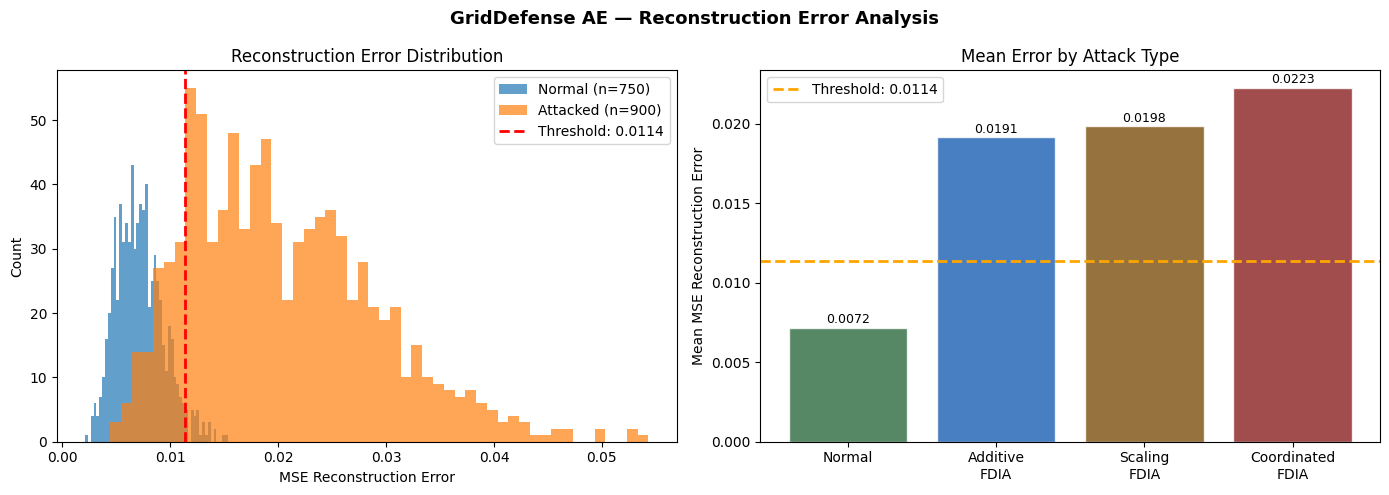


AE STEP 4 COMPLETE
Threshold (mean+2σ) : 0.011375
False positive rate : 4.13%
Attack detection    : 86.33%


In [ ]:
# ============================================================
# GridDefense | AE — Step 4: Test Detection
# Uses global test split (normal + attacked together)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ── Reconstruct full test set ────────────────────────────────

test_pred   = autoencoder.predict(X_test_ae, verbose=0)
test_errors = np.mean(np.square(X_test_ae - test_pred), axis=1)

# Split errors by label using y_test_ae (Attack_Type)
normal_mask = (y_test_ae == 0)
attack_mask = (y_test_ae != 0)

normal_errors  = test_errors[normal_mask]
attacked_errors = test_errors[attack_mask]

print("=" * 60)
print("AE RECONSTRUCTION ERROR — TEST SET")
print("=" * 60)
print(f"\nNormal  : {normal_errors.mean():.6f} mean  |  {normal_errors.std():.6f} std  |  n={len(normal_errors)}")
print(f"Attacked: {attacked_errors.mean():.6f} mean  |  {attacked_errors.std():.6f} std  |  n={len(attacked_errors)}")
print(f"\nAttack/normal ratio: {attacked_errors.mean()/normal_errors.mean():.2f}x")


# ── Threshold from validation normal ────────────────────────

val_pred   = autoencoder.predict(X_val_ae, verbose=0)
val_errors = np.mean(np.square(X_val_ae - val_pred), axis=1)

threshold = val_errors.mean() + 2 * val_errors.std()

print()
print("=" * 60)
print("VALIDATION THRESHOLD")
print("=" * 60)
print(f"Val mean : {val_errors.mean():.6f}")
print(f"Val std  : {val_errors.std():.6f}")
print(f"Threshold: {threshold:.6f}  (mean + 2σ)")


# ── Final detection ──────────────────────────────────────────

false_positives     = (normal_errors  > threshold).sum()
true_positives      = (attacked_errors > threshold).sum()
false_positive_rate = false_positives / len(normal_errors)
detection_rate      = true_positives  / len(attacked_errors)

print()
print("=" * 60)
print("FINAL TEST DETECTION")
print("=" * 60)
print(f"Normal false positives : {false_positives}/{len(normal_errors)} ({false_positive_rate*100:.2f}%)")
print(f"Attacks detected       : {true_positives}/{len(attacked_errors)} ({detection_rate*100:.2f}%)")


# ── Per attack type ──────────────────────────────────────────

print("\nDetection by attack type:")
for attack_name, atype in [("Additive", 1), ("Scaling", 2), ("Coordinated", 3)]:
    mask     = (y_test_ae == atype)
    errs     = test_errors[mask]
    detected = (errs > threshold).sum()
    rate     = detected / len(errs) if len(errs) > 0 else 0
    print(f"  {attack_name:12s}: {detected}/{len(errs)} ({rate*100:.2f}%)  mean_err={errs.mean():.6f}")


# ── Plot ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('GridDefense AE — Reconstruction Error Analysis', fontsize=13, fontweight='bold')

axes[0].hist(normal_errors,  bins=50, alpha=0.7, label=f'Normal (n={len(normal_errors)})')
axes[0].hist(attacked_errors, bins=50, alpha=0.7, label=f'Attacked (n={len(attacked_errors)})')
axes[0].axvline(threshold, linestyle='--', linewidth=2, color='red', label=f'Threshold: {threshold:.4f}')
axes[0].set_title('Reconstruction Error Distribution')
axes[0].set_xlabel('MSE Reconstruction Error')
axes[0].set_ylabel('Count')
axes[0].legend()

categories = ['Normal', 'Additive\nFDIA', 'Scaling\nFDIA', 'Coordinated\nFDIA']
means = [
    normal_errors.mean(),
    test_errors[y_test_ae == 1].mean(),
    test_errors[y_test_ae == 2].mean(),
    test_errors[y_test_ae == 3].mean()
]
colors = ['#2d6a3f', '#1a5fb4', '#7c4f0e', '#8a2020']

bars = axes[1].bar(categories, means, color=colors, alpha=0.8, edgecolor='white')
axes[1].axhline(threshold, linestyle='--', linewidth=2, color='orange', label=f'Threshold: {threshold:.4f}')
axes[1].set_title('Mean Error by Attack Type')
axes[1].set_ylabel('Mean MSE Reconstruction Error')
axes[1].legend()

for bar, val in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.0001,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('ae_detection_results.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print("=" * 60)
print("AE STEP 4 COMPLETE")
print("=" * 60)
print(f"Threshold (mean+2σ) : {threshold:.6f}")
print(f"False positive rate : {false_positive_rate*100:.2f}%")
print(f"Attack detection    : {detection_rate*100:.2f}%")

In [ ]:
# ============================================================
# GridDefense | Random Forest Classifier
# ============================================================
#
# Primary classifier for GridDefense.
#
# Features: 104 (non-redundant)
#   56 raw      : Vm, Va, Pd, Qd
#   14 P_res    : AC active power residual
#   14 Q_res    : AC reactive power residual
#   20 LineFlow : branch apparent power |S|
#
# No scaling required for Random Forest.
# Tree-based models are invariant to monotonic feature scaling.
#
# class_weight='balanced': predefined to compensate for the
# lower training frequency of each attack class relative to Normal
# (3500 Normal vs 1400 samples per attack type).
#
# oob_score=True: provides an out-of-bag training estimate.
#
# Literature:
#   Louppe et al. (2013) — Random Forest theory
#   Ashrafuzzaman et al. (2020) — RF for FDIA on IEEE 14-bus
#
# IMPORTANT:
#   BusBalance excluded — algebraically redundant with P_res.
#   Q_KCL excluded — reserved for physics validation layer.
#   bus_label_* excluded — ground-truth localization labels.
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np
import joblib
import os

print("=" * 60)
print("GridDefense — Random Forest Classifier (Primary)")
print("=" * 60)

# ── Feature set: 104 non-redundant ───────────────────────────

rf_feature_cols = (
    [f'Vm_{i+1}'       for i in range(14)] +
    [f'Va_{i+1}'       for i in range(14)] +
    [f'Pd_{i+1}'       for i in range(14)] +
    [f'Qd_{i+1}'       for i in range(14)] +
    [f'P_res_{i+1}'    for i in range(14)] +
    [f'Q_res_{i+1}'    for i in range(14)] +
    [f'LineFlow_{i+1}' for i in range(20)]
    # BusBalance excluded — = -P_res (algebraic identity, verified)
    # Q_KCL excluded — physics validation layer only
    # bus_label_* excluded — ground-truth labels, never model input
)

print(f"Features : {len(rf_feature_cols)} (non-redundant)")
print(f"Task     : 4-class classification")
print(f"           Normal / Additive / Scaling / Coordinated")
print()

# ── Same split as all other models ───────────────────────────

X_train_rf = df_full.iloc[list(train_idx)][rf_feature_cols].values
y_train_rf = (
    df_full.iloc[list(train_idx)]['Attack_Type']
    .astype(int)
    .values
)

X_val_rf = df_full.iloc[list(val_idx)][rf_feature_cols].values
y_val_rf = (
    df_full.iloc[list(val_idx)]['Attack_Type']
    .astype(int)
    .values
)

X_test_rf = df_full.iloc[list(test_idx)][rf_feature_cols].values
y_test_rf = (
    df_full.iloc[list(test_idx)]['Attack_Type']
    .astype(int)
    .values
)

print(f"Train : {X_train_rf.shape}")
print(f"Val   : {X_val_rf.shape}")
print(f"Test  : {X_test_rf.shape}")
print()

# ── Train ─────────────────────────────────────────────────────

print("Training Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators      = 500,    # Fixed ensemble size for final configuration
    max_depth         = None,   # Fully grown trees
    min_samples_split = 5,      # Light regularisation
    class_weight      = 'balanced',
    oob_score         = True,
    random_state      = 42,
    n_jobs            = -1
)

rf_model.fit(X_train_rf, y_train_rf)

print(f"✓ Trained {rf_model.n_estimators} trees")
print(f"  OOB training estimate : {rf_model.oob_score_:.4f}")
print()

# ── Test evaluation — run once ────────────────────────────────

rf_pred = rf_model.predict(X_test_rf)

acc = accuracy_score(
    y_test_rf,
    rf_pred
)

mf1 = f1_score(
    y_test_rf,
    rf_pred,
    average='macro',
    zero_division=0
)

wf1 = f1_score(
    y_test_rf,
    rf_pred,
    average='weighted',
    zero_division=0
)

# Binary attack detection recall:
# Fraction of attacked samples correctly identified
# as any non-Normal class.

binary_detection_recall = (
    (rf_pred[y_test_rf != 0] != 0).mean() * 100
)

# False-positive rate:
# Fraction of normal samples incorrectly classified
# as an attack.

binary_fpr = (
    (rf_pred[y_test_rf == 0] != 0).mean() * 100
)

print("=" * 60)
print("RF TEST RESULTS")
print("=" * 60)

print(f"\n  4-class accuracy         : {acc * 100:.2f}%")
print(f"  Macro F1                 : {mf1:.4f}")
print(f"  Weighted F1              : {wf1:.4f}")
print(f"  Binary attack recall     : {binary_detection_recall:.2f}%")
print(f"  False-positive rate      : {binary_fpr:.2f}%")
print()

print(
    classification_report(
        y_test_rf,
        rf_pred,
        target_names=[
            'Normal',
            'Additive',
            'Scaling',
            'Coordinated'
        ],
        zero_division=0
    )
)

# ── Feature importance — top 15 ───────────────────────────────

print("=" * 60)
print("FEATURE IMPORTANCE — Top 15")
print("=" * 60)

importances = rf_model.feature_importances_

top15 = np.argsort(importances)[::-1][:15]

for rank, idx in enumerate(top15, 1):
    print(
        f"  {rank:2d}. "
        f"{rf_feature_cols[idx]:<25} "
        f"{importances[idx]:.4f}"
    )

# ── Save locally ──────────────────────────────────────────────

os.makedirs('/content/models', exist_ok=True)

joblib.dump(
    rf_model,
    '/content/models/rf_final.pkl'
)

joblib.dump(
    rf_feature_cols,
    '/content/models/rf_feature_cols.pkl'
)

print()
print("✓ rf_final.pkl saved to /content/models/")
print("✓ rf_feature_cols.pkl saved to /content/models/")
print()

# ── Summary ───────────────────────────────────────────────────

print("=" * 60)
print("SUMMARY")
print("=" * 60)

print(f"  4-class accuracy         : {acc * 100:.2f}%")
print(f"  Macro F1                 : {mf1:.4f}")
print(f"  Weighted F1              : {wf1:.4f}")
print(f"  Binary attack recall     : {binary_detection_recall:.2f}%")
print(f"  False-positive rate      : {binary_fpr:.2f}%")
print()
print("✓ Random Forest classifier configuration complete.")

GridDefense — Random Forest Classifier (Primary)
Features : 104 (non-redundant)
Task     : 4-class classification
           Normal / Additive / Scaling / Coordinated

Train : (7700, 104)
Val   : (1650, 104)
Test  : (1650, 104)

Training Random Forest...
✓ Trained 500 trees
  OOB training estimate : 0.8838

RF TEST RESULTS

  4-class accuracy         : 87.82%
  Macro F1                 : 0.8510
  Weighted F1              : 0.8767
  Binary attack recall     : 94.22%
  False-positive rate      : 4.13%

              precision    recall  f1-score   support

      Normal       0.93      0.96      0.95       750
    Additive       0.85      0.72      0.78       300
     Scaling       0.82      0.86      0.84       300
 Coordinated       0.83      0.85      0.84       300

    accuracy                           0.88      1650
   macro avg       0.86      0.85      0.85      1650
weighted avg       0.88      0.88      0.88      1650

FEATURE IMPORTANCE — Top 15
   1. P_res_7                  

In [ ]:
# ============================================================
# GridDefense | RF Localization — Bus-Level Attack Detection
# ============================================================
#
# Purpose:
#   Identify which buses are suspected to be under attack.
#
# Separate from RF attack-type classifier.
#
# Input:
#   104 physics-enriched features
#
# Output:
#   bus_label_1 ... bus_label_14
#
# Model:
#   MultiOutputClassifier(RandomForestClassifier)
#
# Ground truth:
#   bus_label_1 ... bus_label_14 from Step 7
#
# Evaluation:
#   - Exact match rate
#   - Localization recall
#   - Micro F1
#   - Macro F1
#   - Mean per-bus F1
#   - Hamming loss
#   - Per-attack-type localization
#   - Per-bus F1
#
# IMPORTANT:
#   bus_label columns are ground truth ONLY.
#   They are NEVER used as model inputs.
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score, hamming_loss
import numpy as np
import joblib
import os

print("=" * 60)
print("GridDefense — RF Bus Localization")
print("=" * 60)


# ============================================================
# 1. BUS LABEL COLUMNS — GROUND TRUTH ONLY
# ============================================================

bus_label_cols = [f'bus_label_{i+1}' for i in range(14)]


# ============================================================
# 2. LEAKAGE CHECK
# ============================================================

forbidden_cols = bus_label_cols + ['Label', 'Attack_Type']

assert not any(
    c in rf_feature_cols for c in forbidden_cols
), "LEAKAGE: target/label column found in localization features"

print("✓ No target leakage — labels excluded from features")


# ============================================================
# 3. SAME GLOBAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train_loc = df_full.iloc[list(train_idx)][rf_feature_cols].values
y_train_loc = df_full.iloc[list(train_idx)][bus_label_cols].values

X_val_loc = df_full.iloc[list(val_idx)][rf_feature_cols].values
y_val_loc = df_full.iloc[list(val_idx)][bus_label_cols].values

X_test_loc = df_full.iloc[list(test_idx)][rf_feature_cols].values
y_test_loc = df_full.iloc[list(test_idx)][bus_label_cols].values

print()
print("Dataset shapes:")
print(f"  Train: {X_train_loc.shape} | Labels: {y_train_loc.shape}")
print(f"  Val  : {X_val_loc.shape}   | Labels: {y_val_loc.shape}")
print(f"  Test : {X_test_loc.shape}  | Labels: {y_test_loc.shape}")
print()


# ============================================================
# 4. TRAIN RF LOCALIZATION MODEL
# ============================================================

print("Training RF Localization model...")
print("  14 bus-level RF classifiers × 500 trees")
print()

base_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=1
)

rf_loc = MultiOutputClassifier(
    base_rf,
    n_jobs=-1
)

rf_loc.fit(
    X_train_loc,
    y_train_loc
)

print("✓ RF localization model trained")
print()


# ============================================================
# 5. TEST PREDICTIONS
# ============================================================

y_pred_loc = rf_loc.predict(X_test_loc)


# ============================================================
# 6. ATTACKED SAMPLES ONLY
# ============================================================
#
# Localization is evaluated on samples that actually contain
# at least one attacked bus.
# ============================================================

attacked_mask_loc = y_test_loc.sum(axis=1) > 0

y_true_att = y_test_loc[attacked_mask_loc]
y_pred_att = y_pred_loc[attacked_mask_loc]

print("=" * 60)
print("LOCALIZATION EVALUATION SET")
print("=" * 60)
print(f"  Total test samples       : {len(y_test_loc)}")
print(f"  Attacked test samples    : {len(y_true_att)}")
print(f"  Normal test samples     : {(~attacked_mask_loc).sum()}")
print()


# ============================================================
# 7. EXACT MATCH RATE
# ============================================================
#
# A prediction is correct only if ALL 14 bus labels exactly
# match the ground truth.
# ============================================================

exact_match = (
    (y_true_att == y_pred_att)
    .all(axis=1)
    .mean()
) * 100


# ============================================================
# 8. LOCALIZATION RECALL
# ============================================================
#
# Fraction of the truly attacked buses that were correctly
# identified.
#
# Example:
#   True buses = {3, 8, 10}
#   Predicted  = {3, 10}
#
#   Localization recall = 2 / 3 = 66.7%
# ============================================================

localization_recall_per_sample = []

for i in range(len(y_true_att)):

    true_buses = set(
        np.where(y_true_att[i] == 1)[0]
    )

    pred_buses = set(
        np.where(y_pred_att[i] == 1)[0]
    )

    if len(true_buses) > 0:

        overlap = len(
            true_buses & pred_buses
        ) / len(true_buses)

        localization_recall_per_sample.append(
            overlap
        )

localization_recall = (
    np.mean(localization_recall_per_sample)
) * 100


# ============================================================
# 9. PER-BUS F1
# ============================================================

bus_f1 = []

for b in range(14):

    f1 = f1_score(
        y_true_att[:, b],
        y_pred_att[:, b],
        zero_division=0
    )

    bus_f1.append(f1)

mean_bus_f1 = np.mean(bus_f1) * 100


# ============================================================
# 10. MICRO / MACRO F1
# ============================================================

micro_f1 = f1_score(
    y_true_att,
    y_pred_att,
    average='micro',
    zero_division=0
) * 100

macro_f1 = f1_score(
    y_true_att,
    y_pred_att,
    average='macro',
    zero_division=0
) * 100


# ============================================================
# 11. HAMMING LOSS
# ============================================================
#
# Percentage of all bus labels that were incorrectly predicted.
# ============================================================

h_loss = (
    hamming_loss(
        y_true_att,
        y_pred_att
    )
) * 100


# ============================================================
# 12. OVERALL LOCALIZATION RESULTS
# ============================================================

print("=" * 60)
print("RF LOCALIZATION RESULTS — ATTACKED SAMPLES")
print("=" * 60)

print()
print(f"  Exact match rate    : {exact_match:.1f}%")
print(
    f"  Localization recall : {localization_recall:.1f}%"
)
print(
    "    (fraction of true attacked buses correctly identified)"
)
print(f"  Mean bus F1         : {mean_bus_f1:.1f}%")
print(f"  Micro bus F1        : {micro_f1:.1f}%")
print(f"  Macro bus F1        : {macro_f1:.1f}%")
print(f"  Hamming loss        : {h_loss:.1f}%")
print(
    "    (% of bus labels incorrectly predicted)"
)
print()


# ============================================================
# 13. LOCALIZATION BY ATTACK TYPE
# ============================================================

print("Per attack type localization:")
print()

test_type = df_full.iloc[
    list(test_idx)
]['Attack_Type'].values

for atype, name in [
    (1, 'Additive'),
    (2, 'Scaling'),
    (3, 'Coordinated')
]:

    mask = test_type == atype

    if mask.sum() == 0:
        continue

    yt = y_test_loc[mask]
    yp = y_pred_loc[mask]

    # Exact match
    em = (
        (yt == yp)
        .all(axis=1)
        .mean()
    ) * 100

    # Localization recall
    recall_values = []

    for i in range(len(yt)):

        true_buses = set(
            np.where(yt[i] == 1)[0]
        )

        pred_buses = set(
            np.where(yp[i] == 1)[0]
        )

        if len(true_buses) > 0:

            recall_values.append(
                len(true_buses & pred_buses)
                / len(true_buses)
            )

    type_recall = (
        np.mean(recall_values) * 100
        if recall_values
        else 0
    )

    print(
        f"  {name:<14}: "
        f"exact={em:.1f}%  "
        f"localization recall={type_recall:.1f}%"
    )

print()


# ============================================================
# 14. PER-BUS LOCALIZATION F1
# ============================================================

print("Per-bus localization F1:")
print()

print(
    f"  {'Bus':<6}"
    f"{'F1':>8}"
    f"{'True attacked%':>18}"
    f"{'Pred attacked%':>18}"
)

print("  " + "-" * 54)

for b in range(14):

    true_rate = (
        y_true_att[:, b].mean()
    ) * 100

    pred_rate = (
        y_pred_att[:, b].mean()
    ) * 100

    print(
        f"  Bus {b+1:<3}"
        f"{bus_f1[b]:>8.3f}"
        f"{true_rate:>17.1f}%"
        f"{pred_rate:>17.1f}%"
    )

print()


# ============================================================
# 15. SAVE MODEL
# ============================================================

os.makedirs(
    '/content/models',
    exist_ok=True
)

model_path = (
    '/content/models/'
    'rf_localization.pkl'
)

joblib.dump(
    rf_loc,
    model_path
)

print(
    f"✓ rf_localization.pkl saved to {model_path}"
)
print()


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("=" * 60)
print("LOCALIZATION SUMMARY")
print("=" * 60)

print(
    f"""
GridDefense Bus Localization (RF):

  Exact match         : {exact_match:.1f}%
  Localization recall : {localization_recall:.1f}%
  Mean bus F1         : {mean_bus_f1:.1f}%
  Micro bus F1        : {micro_f1:.1f}%
  Macro bus F1        : {macro_f1:.1f}%
  Hamming loss        : {h_loss:.1f}%

Purpose:
  Identify which buses are suspected to be attacked.

The localization model is separate from the RF attack-type
classifier.

The decision layer can therefore combine:

  AE                 → measurement anomaly evidence
  RF type classifier → attack type
  RF localization    → suspected attacked bus(es)
  Physics layer      → physical consistency evidence
"""
)

print("=" * 60)
print("✓ RF LOCALIZATION COMPLETE")
print("=" * 60)

GridDefense — RF Bus Localization
✓ No target leakage — labels excluded from features

Dataset shapes:
  Train: (7700, 104) | Labels: (7700, 14)
  Val  : (1650, 104)   | Labels: (1650, 14)
  Test : (1650, 104)  | Labels: (1650, 14)

Training RF Localization model...
  14 bus-level RF classifiers × 500 trees

✓ RF localization model trained

LOCALIZATION EVALUATION SET
  Total test samples       : 1650
  Attacked test samples    : 900
  Normal test samples     : 750

RF LOCALIZATION RESULTS — ATTACKED SAMPLES

  Exact match rate    : 55.0%
  Localization recall : 76.4%
    (fraction of true attacked buses correctly identified)
  Mean bus F1         : 78.6%
  Micro bus F1        : 85.3%
  Macro bus F1        : 78.6%
  Hamming loss        : 4.0%
    (% of bus labels incorrectly predicted)

Per attack type localization:

  Additive      : exact=61.0%  localization recall=80.9%
  Scaling       : exact=49.0%  localization recall=70.3%
  Coordinated   : exact=55.0%  localization recall=77.8%


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score
import numpy as np

# ── Define the binary masks using the existing multi-class variables ──
atk_tr_mask   = y_train_rf != 0
atk_val_mask  = y_val_rf != 0
atk_test_mask = y_test_rf != 0

X_tr_atk  = X_train_rf[atk_tr_mask]
X_val_atk = X_val_rf[atk_val_mask]
X_te_atk  = X_test_rf[atk_test_mask]

# ── Use existing localization labels already in your workspace ──
y_tr_atk  = y_train_loc[atk_tr_mask]
y_val_atk = y_val_loc[atk_val_mask]
y_te_atk  = y_test_loc[atk_test_mask]

print(f"Train attack samples: {X_tr_atk.shape[0]}")
print(f"Val   attack samples: {X_val_atk.shape[0]}")
print(f"Test  attack samples: {X_te_atk.shape[0]}")

# ── Build MLP ─────────────────────────────────────────────────────────
tf.random.set_seed(42)

inputs  = keras.Input(shape=(X_tr_atk.shape[1],))
x       = layers.Dense(256, activation='relu')(inputs)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.3)(x)
x       = layers.Dense(128, activation='relu')(x)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.3)(x)
x       = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(14, activation='sigmoid')(x)

mlp_loc = keras.Model(inputs, outputs, name='MLP_Localization')
mlp_loc.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
mlp_loc.summary()

# ── Train ─────────────────────────────────────────────────────────────
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5
)

history = mlp_loc.fit(
    X_tr_atk, y_tr_atk,
    validation_data=(X_val_atk, y_val_atk),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ── Evaluate ──────────────────────────────────────────────────────────
y_pred_proba = mlp_loc.predict(X_te_atk)
y_pred_bin   = (y_pred_proba >= 0.5).astype(int)

exact_match = np.mean(np.all(y_pred_bin == y_te_atk, axis=1)) * 100
micro_f1    = f1_score(y_te_atk, y_pred_bin, average='micro', zero_division=0) * 100
macro_f1    = f1_score(y_te_atk, y_pred_bin, average='macro', zero_division=0) * 100

# False-localization on normal samples
X_norm_test = X_test_rf[~atk_test_mask]
y_norm_pred = (mlp_loc.predict(X_norm_test) >= 0.5).astype(int)
false_loc_rate = np.mean(np.any(y_norm_pred == 1, axis=1)) * 100

print("\n══════════════════════════════════════")
print("       MLP Localization Results       ")
print("══════════════════════════════════════")
print(f"  Exact match:        {exact_match:.1f}%")
print(f"  Micro F1:           {micro_f1:.1f}%")
print(f"  Macro F1:           {macro_f1:.1f}%")
print(f"  Normal false-loc:   {false_loc_rate:.1f}%")
print("══════════════════════════════════════")

print("\n── Comparison Table ──────────────────")
print(f"{'Metric':<22} {'RF':>8} {'LightGBM':>10} {'MLP':>8}")
print("-" * 50)
print(f"{'Exact match':<22} {'55.0%':>8} {'67.4%':>10} {exact_match:>7.1f}%")
print(f"{'Micro F1':<22} {'85.3%':>8} {'82.0%':>10} {micro_f1:>7.1f}%")
print(f"{'Macro F1':<22} {'78.6%':>8} {'81.6%':>10} {macro_f1:>7.1f}%")
print(f"{'Normal false-loc':<22} {'2.8%':>8} {'1.9%':>10} {false_loc_rate:>7.1f}%")

Train attack samples: 4200
Val   attack samples: 900
Test  attack samples: 900


Model: "MLP_Localization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 104)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        26,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 14)             │           910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,478 (275.30 KB)

 Trainable params: 69,710 (272.30 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.1693 - loss: 0.5063 - val_accuracy: 0.2911 - val_loss: 0.4662 - learning_rate: 0.0010
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3767 - loss: 0.3611 - val_accuracy: 0.4589 - val_loss: 0.3576 - learning_rate: 0.0010
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4379 - loss: 0.3302 - val_accuracy: 0.4800 - val_loss: 0.3118 - learning_rate: 0.0010
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4705 - loss: 0.3076 - val_accuracy: 0.4956 - val_loss: 0.2870 - learning_rate: 0.0010
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4900 - loss: 0.2899 - val_accuracy: 0.5111 - val_loss: 0.2793 - learning_rate: 0.0010
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5150 - loss: 0.2727 - val_accuracy: 0.5289 - val_loss: 0.2618 - learning_rate: 0.0010
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5286 - loss: 0.2601 - val_ac

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

# Map binary targets using existing multi-class variables
atk_val_mask = y_val_rf != 0

# Try different thresholds and find best tradeoff
X_norm_val = X_val_rf[~atk_val_mask]
X_val_atk_loc = X_val_rf[atk_val_mask]
y_val_atk_loc = y_val_loc[atk_val_mask]

print(f"{'Threshold':>10} {'False-loc%':>12} {'Exact%':>10} {'MicroF1%':>10}")
print("-" * 45)

for thresh in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    # Normal false-loc
    norm_pred = (mlp_loc.predict(X_norm_val, verbose=0) >= thresh).astype(int)
    fl = np.mean(np.any(norm_pred == 1, axis=1)) * 100

    # Attack performance
    atk_pred = (mlp_loc.predict(X_val_atk_loc, verbose=0) >= thresh).astype(int)
    exact = np.mean(np.all(atk_pred == y_val_atk_loc, axis=1)) * 100
    mf1 = f1_score(y_val_atk_loc, atk_pred, average='micro', zero_division=0) * 100

    print(f"{thresh:>10.2f} {fl:>11.1f}% {exact:>9.1f}% {mf1:>9.1f}%")

 Threshold   False-loc%     Exact%   MicroF1%
---------------------------------------------
      0.30        42.7%      73.7%      92.3%
      0.35        36.9%      73.4%      92.3%
      0.40        33.3%      73.4%      92.3%
      0.45        29.6%      74.0%      92.4%
      0.50        26.4%      73.2%      92.1%
      0.55        21.9%      71.8%      91.5%
      0.60        18.7%      70.0%      91.0%
      0.65        15.9%      69.1%      90.6%
      0.70        12.5%      67.7%      90.0%


In [ ]:
# ── Baseline RF (104 features) ────────────────────────────────────────
rf_loc_base = MultiOutputClassifier(
    RandomForestClassifier(n_estimators=500, random_state=42,
                           class_weight='balanced', min_samples_split=5,
                           n_jobs=-1)   # n_jobs ONLY on inner RF
    # NO n_jobs on MultiOutputClassifier
)
rf_loc_base.fit(X_train_rf, y_train_loc)
print("Baseline RF trained ✓")
base_res = eval_localization(rf_loc_base, X_test_rf, y_test_loc, y_test_bin, "Baseline RF (104 features)")

# ── Topology-aware RF (160 features) ─────────────────────────────────
rf_loc_topo = MultiOutputClassifier(
    RandomForestClassifier(n_estimators=500, random_state=42,
                           class_weight='balanced', min_samples_split=5,
                           n_jobs=-1)
)
rf_loc_topo.fit(X_tr_topo, y_train_loc)
print("Topology RF trained ✓")
topo_res = eval_localization(rf_loc_topo, X_te_topo, y_test_loc, y_test_bin, "Topology RF (160 features)")

# ── Comparison table ──────────────────────────────────────────────────
comp = pd.DataFrame({"Baseline RF": base_res, "Topology RF": topo_res})
comp["Δ (pp)"] = comp["Topology RF"] - comp["Baseline RF"]
print("\n" + "=" * 60)
print("BASELINE vs TOPOLOGY-AWARE RF")
print("=" * 60)
print(comp.round(2).to_string())

Baseline RF trained ✓

--- Baseline RF (104 features) ---
Exact match:      55.00%
Micro F1:         85.30%
Macro F1:         78.59%
Normal false-loc: 2.80%
Topology RF trained ✓

--- Topology RF (160 features) ---
Exact match:      57.56%
Micro F1:         86.35%
Macro F1:         79.52%
Normal false-loc: 3.60%

BASELINE vs TOPOLOGY-AWARE RF
                      Baseline RF  Topology RF  Δ (pp)
Exact match (%)             55.00        57.56    2.56
Micro F1 (%)                85.30        86.35    1.04
Macro F1 (%)                78.59        79.52    0.93
Normal false-loc (%)         2.80         3.60    0.80


In [ ]:
import numpy as np
from sklearn.metrics import f1_score

# ── Robust probability extraction ─────────────────────────────────────
def get_bus_probas(model, X):
    probas = []
    for est in model.estimators_:
        p = est.predict_proba(X)
        classes = est.classes_
        if 1 not in classes:
            probas.append(np.zeros(X.shape[0]))
        else:
            idx = np.where(classes == 1)[0][0]
            probas.append(p[:, idx])
    return np.column_stack(probas)

val_probas  = get_bus_probas(rf_loc_topo, X_val_topo)
test_probas = get_bus_probas(rf_loc_topo, X_te_topo)

print(f"Val probas:  {val_probas.shape}  | y_val_loc:  {y_val_loc.shape}")
print(f"Test probas: {test_probas.shape} | y_test_loc: {y_test_loc.shape}")

# ── Guards ────────────────────────────────────────────────────────────
assert val_probas.shape  == y_val_loc.shape,  "Val proba/label shape mismatch"
assert test_probas.shape == y_test_loc.shape, "Test proba/label shape mismatch"
assert len(y_val_bin)  == len(y_val_loc),  "Val bin/loc length mismatch"
assert len(y_test_bin) == len(y_test_loc), "Test bin/loc length mismatch"

atk_val  = y_val_bin  == 1
norm_val = y_val_bin  == 0
atk_te   = y_test_bin == 1
norm_te  = y_test_bin == 0

assert np.any(atk_val),  "No attacked validation samples"
assert np.any(norm_val), "No normal validation samples"
assert np.any(atk_te),   "No attacked test samples"
assert np.any(norm_te),  "No normal test samples"
print("All guards passed ✓")

# ── Threshold search on validation only ───────────────────────────────
FALSE_LOC_LIMIT = 0.05
best_exact  = -1
best_thresh = None
best_metrics = {}

for thresh in np.arange(0.20, 0.71, 0.01):
    y_pred_val = (val_probas >= thresh).astype(int)
    fl = np.mean(np.any(y_pred_val[norm_val] == 1, axis=1))
    if fl > FALSE_LOC_LIMIT:
        continue
    exact = np.mean(np.all(y_pred_val[atk_val] == y_val_loc[atk_val], axis=1))
    micro = f1_score(y_val_loc[atk_val], y_pred_val[atk_val], average='micro', zero_division=0)
    macro = f1_score(y_val_loc[atk_val], y_pred_val[atk_val], average='macro', zero_division=0)
    if exact > best_exact:
        best_exact  = exact
        best_thresh = thresh
        best_metrics = {'exact': exact*100, 'micro': micro*100,
                        'macro': macro*100, 'fl': fl*100}

if best_thresh is None:
    raise ValueError("No threshold met ≤5% false-loc on validation. Relax FALSE_LOC_LIMIT.")

print(f"\nBest val threshold: {best_thresh:.2f}")
print(f"  Val exact match:  {best_metrics['exact']:.1f}%")
print(f"  Val micro F1:     {best_metrics['micro']:.1f}%")
print(f"  Val macro F1:     {best_metrics['macro']:.1f}%")
print(f"  Val false-loc:    {best_metrics['fl']:.1f}%")

# ── Apply to test set ONCE ────────────────────────────────────────────
y_pred_tuned = (test_probas >= best_thresh).astype(int)

exact_test = np.mean(np.all(y_pred_tuned[atk_te] == y_test_loc[atk_te], axis=1)) * 100
micro_test = f1_score(y_test_loc[atk_te], y_pred_tuned[atk_te], average='micro', zero_division=0) * 100
macro_test = f1_score(y_test_loc[atk_te], y_pred_tuned[atk_te], average='macro', zero_division=0) * 100
fl_test    = np.mean(np.any(y_pred_tuned[norm_te] == 1, axis=1)) * 100

print(f"\n── Test Results (thresh={best_thresh:.2f}) ────────────────────")
print(f"{'Metric':<22} {'Topo RF default':>16} {'Tuned':>10}")
print("-" * 50)
print(f"{'Exact match':<22} {'57.6%':>16} {exact_test:>9.1f}%")
print(f"{'Micro F1':<22} {'86.3%':>16} {micro_test:>9.1f}%")
print(f"{'Macro F1':<22} {'79.5%':>16} {macro_test:>9.1f}%")
print(f"{'Normal false-loc':<22} {'3.6%':>16} {fl_test:>9.1f}%")
print(f"\n(Val false-loc={best_metrics['fl']:.1f}% → Test false-loc={fl_test:.1f}%)")

Val probas:  (1650, 14)  | y_val_loc:  (1650, 14)
Test probas: (1650, 14) | y_test_loc: (1650, 14)
All guards passed ✓

Best val threshold: 0.47
  Val exact match:  58.7%
  Val micro F1:     87.2%
  Val macro F1:     80.7%
  Val false-loc:    4.9%

── Test Results (thresh=0.47) ────────────────────
Metric                  Topo RF default      Tuned
--------------------------------------------------
Exact match                       57.6%      60.0%
Micro F1                          86.3%      87.6%
Macro F1                          79.5%      80.8%
Normal false-loc                   3.6%       4.1%

(Val false-loc=4.9% → Test false-loc=4.1%)


In [ ]:
# ============================================================
# GridDefense — Extended Topology RF Localization (172 features)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. Second-order neighbors: exactly two edges away
#    Exclude the target bus and all its direct neighbors.
#    Based on the existing NEIGHBORS adjacency dictionary.
# ------------------------------------------------------------

NEIGHBORS_2 = {
    3:  [1, 5, 7, 9],
    11: [5, 12, 13],
    14: [4, 6, 10, 12],
}

# ------------------------------------------------------------
# 2. Extended topology feature generation
#    160 first-order features + 12 second-order features = 172
# ------------------------------------------------------------

def add_topo_extended(X_arr, feat_names):
    """Add first-order topology features and 12 second-order features."""

    X_arr = np.asarray(X_arr)
    df = pd.DataFrame(X_arr, columns=feat_names)
    new_cols = {}

    # First-order topology features: 4 per bus = 56 features
    for bus in range(1, 15):
        neighbors = NEIGHBORS[bus]

        own_vm = df[f"Vm_{bus}"].to_numpy()
        own_va = df[f"Va_{bus}"].to_numpy()

        # Neighbor voltage magnitude
        neigh_vm = df[
            [f"Vm_{n}" for n in neighbors]
        ].to_numpy().mean(axis=1)

        new_cols[f"neigh_Vm_{bus}"] = neigh_vm
        new_cols[f"diff_Vm_{bus}"] = own_vm - neigh_vm

        # Circular mean of neighboring voltage angles
        neigh_angles = np.deg2rad(
            df[[f"Va_{n}" for n in neighbors]].to_numpy()
        )

        neigh_va = np.rad2deg(
            np.arctan2(
                np.sin(neigh_angles).mean(axis=1),
                np.cos(neigh_angles).mean(axis=1)
            )
        )

        new_cols[f"neigh_Va_{bus}"] = neigh_va
        new_cols[f"diff_Va_{bus}"] = (
            (own_va - neigh_va + 180) % 360
        ) - 180

    # Second-order topology features: 4 per selected bus = 12
    for bus, n2_list in NEIGHBORS_2.items():
        own_va = df[f"Va_{bus}"].to_numpy()
        own_vm = df[f"Vm_{bus}"].to_numpy()

        # Second-order circular mean of voltage angles
        n2_angles = np.deg2rad(
            df[[f"Va_{n}" for n in n2_list]].to_numpy()
        )

        n2_va = np.rad2deg(
            np.arctan2(
                np.sin(n2_angles).mean(axis=1),
                np.cos(n2_angles).mean(axis=1)
            )
        )

        new_cols[f"neigh2_Va_{bus}"] = n2_va
        new_cols[f"diff2_Va_{bus}"] = (
            (own_va - n2_va + 180) % 360
        ) - 180

        # Second-order voltage magnitude
        n2_vm = df[
            [f"Vm_{n}" for n in n2_list]
        ].to_numpy().mean(axis=1)

        new_cols[f"neigh2_Vm_{bus}"] = n2_vm
        new_cols[f"diff2_Vm_{bus}"] = own_vm - n2_vm

    # Preserve original features first, then append new features
    X_extended = np.hstack([
        X_arr,
        pd.DataFrame(new_cols).to_numpy()
    ])

    return X_extended


# ------------------------------------------------------------
# 3. Generate features for each split
# ------------------------------------------------------------

assert X_train_rf.shape[1] == len(full_feature_names)
assert X_val_rf.shape[1] == len(full_feature_names)
assert X_test_rf.shape[1] == len(full_feature_names)

X_tr_ext = add_topo_extended(X_train_rf, full_feature_names)
X_val_ext = add_topo_extended(X_val_rf, full_feature_names)
X_te_ext = add_topo_extended(X_test_rf, full_feature_names)

assert X_tr_ext.shape[1] == 172
assert X_val_ext.shape[1] == 172
assert X_te_ext.shape[1] == 172

print("Extended feature shapes:")
print("Train:", X_tr_ext.shape)
print("Val:  ", X_val_ext.shape)
print("Test: ", X_te_ext.shape)
print("Feature count check passed.")

# ------------------------------------------------------------
# 4. Train the extended Random Forest localization model
# ------------------------------------------------------------

rf_loc_ext = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_split=5,
        n_jobs=-1
    ),
    n_jobs=-1
)

rf_loc_ext.fit(X_tr_ext, y_train_loc)

print("Extended RF trained successfully.")

# ------------------------------------------------------------
# 5. Tune the shared threshold on validation data only
#    Constraint: normal false-localization <= 5%
#    Objective: maximize exact match on attacked validation rows
# ------------------------------------------------------------

val_probas_ext = get_bus_probas(rf_loc_ext, X_val_ext)

assert val_probas_ext.shape == y_val_loc.shape

best_exact = -1
best_thresh_ext = None
best_metrics_ext = {}

print("\nSearching validation thresholds...")

for thresh in np.arange(0.20, 0.71, 0.01):
    yp_val = (val_probas_ext >= thresh).astype(int)

    val_fl = np.mean(
        np.any(yp_val[norm_val] == 1, axis=1)
    )

    if val_fl > 0.05:
        continue

    val_exact = np.mean(
        np.all(
            yp_val[atk_val] == y_val_loc[atk_val],
            axis=1
        )
    )

    val_micro = f1_score(
        y_val_loc[atk_val],
        yp_val[atk_val],
        average="micro",
        zero_division=0
    )

    if val_exact > best_exact:
        best_exact = val_exact
        best_thresh_ext = float(thresh)

        best_metrics_ext = {
            "exact": val_exact * 100,
            "micro": val_micro * 100,
            "false_loc": val_fl * 100
        }

if best_thresh_ext is None:
    raise ValueError(
        "No threshold met the 5% validation false-localization constraint."
    )

print(f"Best validation threshold: {best_thresh_ext:.2f}")
print(f"Validation exact match: {best_metrics_ext['exact']:.1f}%")
print(f"Validation micro F1: {best_metrics_ext['micro']:.1f}%")
print(f"Validation false-localization: {best_metrics_ext['false_loc']:.1f}%")

# ------------------------------------------------------------
# 6. Evaluate on the test set once using the frozen threshold
# ------------------------------------------------------------

test_probas_ext = get_bus_probas(rf_loc_ext, X_te_ext)

assert test_probas_ext.shape == y_test_loc.shape

yp_ext = (test_probas_ext >= best_thresh_ext).astype(int)

exact_ext = np.mean(
    np.all(
        yp_ext[atk_te] == y_test_loc[atk_te],
        axis=1
    )
) * 100

micro_ext = f1_score(
    y_test_loc[atk_te],
    yp_ext[atk_te],
    average="micro",
    zero_division=0
) * 100

macro_ext = f1_score(
    y_test_loc[atk_te],
    yp_ext[atk_te],
    average="macro",
    zero_division=0
) * 100

fl_ext = np.mean(
    np.any(yp_ext[norm_te] == 1, axis=1)
) * 100

# ------------------------------------------------------------
# 7. Compare with the existing 160-feature tuned model
# ------------------------------------------------------------

print(
    f"\nExtended RF (172 features, threshold={best_thresh_ext:.2f})"
)
print(f"{'Metric':<24} {'Tuned 160':>12} {'Extended 172':>15}")
print("-" * 53)
print(f"{'Exact match':<24} {'60.0%':>12} {exact_ext:>14.1f}%")
print(f"{'Micro F1':<24} {'87.6%':>12} {micro_ext:>14.1f}%")
print(f"{'Macro F1':<24} {'80.8%':>12} {macro_ext:>14.1f}%")
print(f"{'Normal false-loc':<24} {'4.1%':>12} {fl_ext:>14.1f}%")

print(
    f"\nValidation false-loc: {best_metrics_ext['false_loc']:.1f}%"
    f" | Test false-loc: {fl_ext:.1f}%"
)

Extended feature shapes:
Train: (7700, 172)
Val:   (1650, 172)
Test:  (1650, 172)
Feature count check passed.
Extended RF trained successfully.

Searching validation thresholds...
Best validation threshold: 0.46
Validation exact match: 60.7%
Validation micro F1: 88.2%
Validation false-localization: 4.9%

Extended RF (172 features, threshold=0.46)
Metric                      Tuned 160    Extended 172
-----------------------------------------------------
Exact match                     60.0%           61.4%
Micro F1                        87.6%           88.2%
Macro F1                        80.8%           81.5%
Normal false-loc                 4.1%            4.7%

Validation false-loc: 4.9% | Test false-loc: 4.7%


In [ ]:
# ── Per-attack breakdown + per-bus error for 172-feature extended model ──────

from sklearn.metrics import f1_score
import numpy as np

print("=" * 55)
print("  Extended Topo RF (172-feat) — Per-Attack Breakdown")
print("=" * 55)

attack_types = {1: 'FDIA_Vm', 2: 'FDIA_Va', 3: 'FDIA_Mixed'}
for atype, aname in attack_types.items():
    mask = (y_test_rf == atype).ravel()
    exact = np.mean(np.all(yp_ext[mask] == y_test_loc[mask], axis=1)) * 100
    micro = f1_score(y_test_loc[mask], yp_ext[mask],
                     average='micro', zero_division=0) * 100
    macro = f1_score(y_test_loc[mask], yp_ext[mask],
                     average='macro', zero_division=0) * 100
    # Miss counts (model predicts 0, true is 1) and false flags (pred 1, true 0)
    tp_mask_rows = mask
    misses = np.sum((yp_ext[tp_mask_rows] == 0) & (y_test_loc[tp_mask_rows] == 1))
    fflags = np.sum((yp_ext[tp_mask_rows] == 1) & (y_test_loc[tp_mask_rows] == 0))
    print(f"\n{aname}  (n={mask.sum()})")
    print(f"  Exact={exact:.1f}%  µF1={micro:.1f}%  MacroF1={macro:.1f}%")
    print(f"  Missed labels={misses}  False flags={fflags}")

print("\n" + "=" * 55)
print("  Extended Topo RF (172-feat) — Per-Bus Error Rate")
print("=" * 55)

atk_te = (y_test_rf != 0).ravel()
errors_ext = yp_ext[atk_te] != y_test_loc[atk_te]
miss_ext   = ((yp_ext[atk_te] == 0) & (y_test_loc[atk_te] == 1))
flag_ext   = ((yp_ext[atk_te] == 1) & (y_test_loc[atk_te] == 0))

print(f"\n{'Bus':>4} {'Error%':>7} {'Missed':>7} {'FalseFlg':>9}")
print("-" * 32)
for i in range(14):
    err_rate = errors_ext[:, i].mean() * 100
    missed   = miss_ext[:, i].sum()
    flagged  = flag_ext[:, i].sum()
    marker   = " ◄" if i+1 in [3, 11, 14] else ""
    print(f"  {i+1:>2} {err_rate:>7.1f}% {missed:>7} {flagged:>9}{marker}")

print("\n◄ = buses targeted by 2nd-order neighbor features")

# Quick comparison vs 160-feat for buses 3, 11, 14
print("\n" + "-" * 55)
print("  Sanity check: compare to 160-feat model (same buses)")
print("  (run only if y_pred_topo_tuned is still in session)")
try:
    errors_160 = y_pred_topo_tuned[atk_te] != y_test_loc[atk_te]
    for bus in [3, 11, 14]:
        i = bus - 1
        r160 = errors_160[:, i].mean() * 100
        r172 = errors_ext[:, i].mean() * 100
        delta = r160 - r172
        sign  = "↓" if delta > 0 else "↑"
        print(f"  Bus {bus}: 160-feat={r160:.1f}%  172-feat={r172:.1f}%  "
              f"Δ={abs(delta):.1f}%{sign}")
except NameError:
    print("  (y_pred_topo_tuned not in session — skip comparison)")

  Extended Topo RF (172-feat) — Per-Attack Breakdown

FDIA_Vm  (n=300)
  Exact=65.7%  µF1=89.1%  MacroF1=82.0%
  Missed labels=106  False flags=13

FDIA_Va  (n=300)
  Exact=52.0%  µF1=83.3%  MacroF1=77.5%
  Missed labels=163  False flags=12

FDIA_Mixed  (n=300)
  Exact=66.7%  µF1=91.2%  MacroF1=84.2%
  Missed labels=115  False flags=6

  Extended Topo RF (172-feat) — Per-Bus Error Rate

 Bus  Error%  Missed  FalseFlg
--------------------------------
   1     0.0%       0         0
   2     2.7%      23         1
   3     4.9%      42         2 ◄
   4     3.8%      31         3
   5     3.0%      26         1
   6     2.8%      23         2
   7     2.9%      20         6
   8     3.0%      26         1
   9     3.7%      30         3
  10     3.7%      32         1
  11     3.1%      25         3 ◄
  12     3.6%      30         2
  13     3.8%      33         1
  14     5.3%      43         5 ◄

◄ = buses targeted by 2nd-order neighbor features

----------------------------------------

In [ ]:
# Save the 172-feat model + threshold to Drive
import joblib, os
save_path = '/content/drive/MyDrive/GridDefense/'
joblib.dump(rf_loc_ext, save_path + 'rf_loc_ext_172feat.pkl')
np.save(save_path + 'loc_ext_threshold.npy', np.array([best_thresh_ext]))
print(f"Saved. Threshold = {best_thresh_ext}")

Saved. Threshold = 0.46000000000000024


In [ ]:
# ── Va-specific threshold tuning ─────────────────────────────────────────────

import numpy as np
from sklearn.metrics import f1_score

# ── You need type classifier predictions on val and test ──────────────────────
# rf_type is your 4-class type classifier (Normal/Vm/Va/Mixed)
# If predictions aren't saved, recompute:
# y_val_type_pred  = rf_type.predict(X_val_rf)   # X_val_rf = 104-feat val set
# y_test_type_pred = rf_type.predict(X_test_rf)
# (adjust variable names to match your session)

# Assuming val_probas_ext and test_probas_ext are the 14-bus probability arrays
# and y_val_rf, y_test_rf are ground-truth type labels

FALSE_LOC_LIMIT = 0.05

norm_val = (y_val_rf == 0).ravel()
atk_val  = (y_val_rf != 0).ravel()
va_val   = (y_val_rf == 2).ravel()
nva_val  = atk_val & ~va_val   # Vm + Mixed

print("=" * 60)
print("  Va-specific threshold search")
print("  Base threshold (Vm/Mixed): 0.47  (already tuned)")
print("=" * 60)

best_exact = -1
best_va_thresh = None
best_fl = None

for va_thresh in np.arange(0.25, 0.50, 0.01):
    # Apply different thresholds by attack type (on val)
    y_pred_val = np.zeros_like(val_probas_ext, dtype=int)
    y_pred_val[va_val]  = (val_probas_ext[va_val]  >= va_thresh).astype(int)
    y_pred_val[nva_val] = (val_probas_ext[nva_val] >= 0.47).astype(int)
    y_pred_val[norm_val] = (val_probas_ext[norm_val] >= 0.47).astype(int)  # normal uses base

    fl = np.mean(np.any(y_pred_val[norm_val] == 1, axis=1))
    if fl > FALSE_LOC_LIMIT:
        continue

    exact = np.mean(np.all(y_pred_val[atk_val] == y_val_loc[atk_val], axis=1))
    va_exact = np.mean(np.all(y_pred_val[va_val] == y_val_loc[va_val], axis=1))

    if exact > best_exact:
        best_exact = exact
        best_va_thresh = va_thresh
        best_fl = fl
        best_va_exact = va_exact

print(f"\n  Best Va threshold : {best_va_thresh:.2f}")
print(f"  Val exact match   : {best_exact*100:.1f}%  (was {60.0:.1f}% flat-threshold)")
print(f"  Val Va exact      : {best_va_exact*100:.1f}%")
print(f"  Val false-loc rate: {best_fl*100:.1f}%  (limit={FALSE_LOC_LIMIT*100:.0f}%)")

# ── Apply to test set ─────────────────────────────────────────────────────────
if best_va_thresh is not None:
    norm_te = (y_test_rf == 0).ravel()
    atk_te  = (y_test_rf != 0).ravel()
    va_te   = (y_test_rf == 2).ravel()
    nva_te  = atk_te & ~va_te

    yp_va_tuned = np.zeros_like(test_probas_ext, dtype=int)
    yp_va_tuned[va_te]   = (test_probas_ext[va_te]   >= best_va_thresh).astype(int)
    yp_va_tuned[nva_te]  = (test_probas_ext[nva_te]  >= 0.47).astype(int)
    yp_va_tuned[norm_te] = (test_probas_ext[norm_te] >= 0.47).astype(int)

    fl_te    = np.mean(np.any(yp_va_tuned[norm_te] == 1, axis=1))
    exact_te = np.mean(np.all(yp_va_tuned[atk_te] == y_test_loc[atk_te], axis=1))
    micro_te = f1_score(y_test_loc[atk_te], yp_va_tuned[atk_te], average='micro', zero_division=0)

    print("\n" + "=" * 60)
    print("  TEST SET — Va-specific threshold results")
    print("=" * 60)
    print(f"  Va thresh={best_va_thresh:.2f}, Vm/Mixed thresh=0.47")
    print(f"  Exact match : {exact_te*100:.1f}%")
    print(f"  µF1         : {micro_te*100:.1f}%")
    print(f"  False-loc   : {fl_te*100:.1f}%")

    # Per-attack breakdown
    print()
    for atype, aname in [(1,'FDIA_Vm'),(2,'FDIA_Va'),(3,'FDIA_Mixed')]:
        mask = (y_test_rf == atype).ravel()
        ex = np.mean(np.all(yp_va_tuned[mask] == y_test_loc[mask], axis=1))*100
        mf = f1_score(y_test_loc[mask], yp_va_tuned[mask], average='micro', zero_division=0)*100
        print(f"  {aname}: Exact={ex:.1f}%  µF1={mf:.1f}%")

  Va-specific threshold search
  Base threshold (Vm/Mixed): 0.47  (already tuned)

  Best Va threshold : 0.30
  Val exact match   : 62.2%  (was 60.0% flat-threshold)
  Val Va exact      : 56.0%
  Val false-loc rate: 4.9%  (limit=5%)

  TEST SET — Va-specific threshold results
  Va thresh=0.30, Vm/Mixed thresh=0.47
  Exact match : 64.3%
  µF1         : 89.5%
  False-loc   : 4.3%

  FDIA_Vm: Exact=64.3%  µF1=88.6%
  FDIA_Va: Exact=63.0%  µF1=88.6%
  FDIA_Mixed: Exact=65.7%  µF1=90.9%


In [ ]:
# ── Session variable check — run before retraining ───────────────────────────
import numpy as np

checks = {
    'X_train_ext': 'X_train_ext',
    'X_val_ext':   'X_val_ext',
    'X_test_ext':  'X_test_ext',
    'y_train_loc': 'y_train_loc',
    'y_val_loc':   'y_val_loc',
    'y_test_loc':  'y_test_loc',
    'y_train_rf':  'y_train_rf',
    'y_val_rf':    'y_val_rf',
    'y_test_rf':   'y_test_rf',
    'X_val_rf':    'X_val_rf',
    'X_test_rf':   'X_test_rf',
    'rf_type':     'rf_type',
}

print("Variable check:")
for name, var in checks.items():
    try:
        obj = eval(var)
        shape = obj.shape if hasattr(obj, 'shape') else 'object'
        print(f"  ✓ {name:<18} {shape}")
    except NameError:
        print(f"  ✗ {name:<18} NOT IN SESSION")

Variable check:
  ✗ X_train_ext        NOT IN SESSION
  ✓ X_val_ext          (1650, 172)
  ✗ X_test_ext         NOT IN SESSION
  ✓ y_train_loc        (7700, 14)
  ✓ y_val_loc          (1650, 14)
  ✓ y_test_loc         (1650, 14)
  ✓ y_train_rf         (7700,)
  ✓ y_val_rf           (1650,)
  ✓ y_test_rf          (1650,)
  ✓ X_val_rf           (1650, 104)
  ✓ X_test_rf          (1650, 104)
  ✗ rf_type            NOT IN SESSION


In [ ]:
# ============================================================
# GRIDDEFENSE — Realistic Dual-Threshold Localization
# 172-feature localization probabilities
# 104-feature attack-type classifier
# ============================================================

import numpy as np
from sklearn.metrics import f1_score, accuracy_score

BASE_THRESHOLD = 0.47
FALSE_LOC_LIMIT = 0.05

# ------------------------------------------------------------
# STEP 1: Validate shapes and model configuration
# ------------------------------------------------------------

print("=" * 65)
print("GRIDDEFENSE — DUAL-THRESHOLD LOCALIZATION")
print("=" * 65)

# Confirm the attack-type classifier's input feature count
expected_features = getattr(rf_model, "n_features_in_", None)

print("\nChecking feature dimensions...")
print("X_val_rf:", X_val_rf.shape)
print("X_test_rf:", X_test_rf.shape)
print("Expected features for rf_model:", expected_features)
print("Validation localization probabilities:", val_probas_ext.shape)
print("Test localization probabilities:", test_probas_ext.shape)

assert X_val_rf.ndim == 2 and X_test_rf.ndim == 2
assert X_val_rf.shape[1] == X_test_rf.shape[1]

if expected_features is not None:
    assert X_val_rf.shape[1] == expected_features, (
        f"rf_model expects {expected_features} features, "
        f"but X_val_rf has {X_val_rf.shape[1]}."
    )

assert val_probas_ext.ndim == 2 and test_probas_ext.ndim == 2
assert val_probas_ext.shape[1] == 14
assert test_probas_ext.shape[1] == 14

assert val_probas_ext.shape[0] == len(y_val_rf) == len(y_val_loc)
assert test_probas_ext.shape[0] == len(y_test_rf) == len(y_test_loc)

assert X_val_rf.shape[0] == len(y_val_rf)
assert X_test_rf.shape[0] == len(y_test_rf)

assert np.isfinite(val_probas_ext).all()
assert np.isfinite(test_probas_ext).all()

assert np.all((val_probas_ext >= 0) & (val_probas_ext <= 1))
assert np.all((test_probas_ext >= 0) & (test_probas_ext <= 1))

# Confirm localization targets contain 14 bus labels
assert np.asarray(y_val_loc).shape[1] == 14
assert np.asarray(y_test_loc).shape[1] == 14

# Confirm ground-truth attack-type encoding
expected_classes = {0, 1, 2, 3}
actual_val_classes = set(np.unique(np.asarray(y_val_rf).ravel()))
actual_test_classes = set(np.unique(np.asarray(y_test_rf).ravel()))

assert actual_val_classes == expected_classes, (
    f"Unexpected validation classes: {actual_val_classes}"
)
assert actual_test_classes == expected_classes, (
    f"Unexpected test classes: {actual_test_classes}"
)

print("\nBasic shape and label checks passed.")

# ------------------------------------------------------------
# STEP 2: Predict attack types using the trained type classifier
# ------------------------------------------------------------

y_val_type_pred = np.asarray(rf_model.predict(X_val_rf)).ravel()
y_test_type_pred = np.asarray(rf_model.predict(X_test_rf)).ravel()

assert len(y_val_type_pred) == len(y_val_rf)
assert len(y_test_type_pred) == len(y_test_rf)

assert set(np.unique(y_val_type_pred)).issubset(expected_classes)
assert set(np.unique(y_test_type_pred)).issubset(expected_classes)

print("\nType-class predictions completed.")
print(
    "Validation routing accuracy:",
    f"{accuracy_score(np.asarray(y_val_rf).ravel(), y_val_type_pred)*100:.2f}%"
)

# ------------------------------------------------------------
# STEP 3: Prepare validation masks
# Ground-truth labels are used for scoring, NOT routing.
# ------------------------------------------------------------

y_val_type = np.asarray(y_val_rf).ravel()
y_test_type = np.asarray(y_test_rf).ravel()

y_val_loc_arr = np.asarray(y_val_loc, dtype=int)
y_test_loc_arr = np.asarray(y_test_loc, dtype=int)

norm_val = (y_val_type == 0)
atk_val = (y_val_type != 0)

# Route by predicted attack type
va_routed_val = (y_val_type_pred == 2)
nva_routed_val = ~va_routed_val

assert norm_val.any(), "No normal validation samples found."
assert atk_val.any(), "No attacked validation samples found."
assert va_routed_val.any(), (
    "The type classifier predicted no Va samples on validation."
)

# ------------------------------------------------------------
# STEP 4: Tune Va threshold on VALIDATION ONLY
# All non-Va predictions retain the fixed base threshold.
# ------------------------------------------------------------

best_exact = -1.0
best_va_thresh = None
best_fl = None
best_va_exact = None

print("\n" + "=" * 65)
print("VALIDATION — Va-specific threshold search")
print("=" * 65)
print(f"Base threshold for non-Va routes: {BASE_THRESHOLD:.2f}")
print(f"Normal false-localization limit: {FALSE_LOC_LIMIT*100:.1f}%")

for va_thresh in np.arange(0.25, 0.50, 0.01):
    y_pred_val = np.zeros_like(val_probas_ext, dtype=int)

    y_pred_val[va_routed_val] = (
        val_probas_ext[va_routed_val] >= va_thresh
    ).astype(int)

    y_pred_val[nva_routed_val] = (
        val_probas_ext[nva_routed_val] >= BASE_THRESHOLD
    ).astype(int)

    # False-localization rate among true normal samples
    fl = np.mean(
        np.any(y_pred_val[norm_val] == 1, axis=1)
    )

    if fl > FALSE_LOC_LIMIT:
        continue

    # Exact match among all true attacked validation samples
    exact = np.mean(
        np.all(
            y_pred_val[atk_val] == y_val_loc_arr[atk_val],
            axis=1
        )
    )

    # Diagnostic only: Va exact match on true Va samples
    va_val_mask = (y_val_type == 2)
    va_exact = np.mean(
        np.all(
            y_pred_val[va_val_mask] == y_val_loc_arr[va_val_mask],
            axis=1
        )
    )

    # Maximize overall attacked-sample exact match.
    # In a tie, prefer the higher Va threshold.
    if (
        exact > best_exact
        or (
            np.isclose(exact, best_exact)
            and best_va_thresh is not None
            and va_thresh > best_va_thresh
        )
    ):
        best_exact = exact
        best_va_thresh = float(va_thresh)
        best_fl = fl
        best_va_exact = va_exact

if best_va_thresh is None:
    raise RuntimeError(
        "No candidate Va threshold satisfied the validation "
        "false-localization constraint. Do not evaluate the test set "
        "with an unselected threshold."
    )

print(f"\nSelected Va threshold: {best_va_thresh:.2f}")
print(f"Validation exact match: {best_exact*100:.2f}%")
print(f"Validation Va exact match: {best_va_exact*100:.2f}%")
print(f"Validation false-localization: {best_fl*100:.2f}%")

# ------------------------------------------------------------
# STEP 5: Apply frozen routing and thresholds to TEST ONCE
# ------------------------------------------------------------

norm_te = (y_test_type == 0)
atk_te = (y_test_type != 0)

assert norm_te.any(), "No normal test samples found."
assert atk_te.any(), "No attacked test samples found."

va_routed_te = (y_test_type_pred == 2)
nva_routed_te = ~va_routed_te

yp_realistic = np.zeros_like(test_probas_ext, dtype=int)

yp_realistic[va_routed_te] = (
    test_probas_ext[va_routed_te] >= best_va_thresh
).astype(int)

yp_realistic[nva_routed_te] = (
    test_probas_ext[nva_routed_te] >= BASE_THRESHOLD
).astype(int)

# Score using ground-truth labels, never for routing
fl_te = np.mean(
    np.any(yp_realistic[norm_te] == 1, axis=1)
)

exact_te = np.mean(
    np.all(
        yp_realistic[atk_te] == y_test_loc_arr[atk_te],
        axis=1
    )
)

micro_te = f1_score(
    y_test_loc_arr[atk_te],
    yp_realistic[atk_te],
    average="micro",
    zero_division=0
)

macro_te = f1_score(
    y_test_loc_arr[atk_te],
    yp_realistic[atk_te],
    average="macro",
    zero_division=0
)

print("\n" + "=" * 65)
print("TEST — REALISTIC PREDICTED-TYPE ROUTING")
print("=" * 65)
print(f"Va threshold: {best_va_thresh:.2f}")
print(f"Non-Va threshold: {BASE_THRESHOLD:.2f}")
print(f"Total test samples: {len(y_test_type)}")
print(f"Normal test samples: {norm_te.sum()}")
print(f"Attacked test samples: {atk_te.sum()}")
print(f"Overall exact match (attacked samples): {exact_te*100:.2f}%")
print(f"Micro F1 (attacked samples): {micro_te*100:.2f}%")
print(f"Macro F1 (attacked samples): {macro_te*100:.2f}%")
print(f"Normal false-localization: {fl_te*100:.2f}%")
print(f"Meets 5% false-localization limit: {fl_te <= FALSE_LOC_LIMIT}")

# ------------------------------------------------------------
# STEP 6: Per-attack breakdown and routing diagnostics
# ------------------------------------------------------------

print("\nPer-attack results:")
for atype, aname in [
    (1, "FDIA_Vm"),
    (2, "FDIA_Va"),
    (3, "FDIA_Mixed")
]:
    mask = (y_test_type == atype)

    ex = np.mean(
        np.all(
            yp_realistic[mask] == y_test_loc_arr[mask],
            axis=1
        )
    ) * 100

    mf = f1_score(
        y_test_loc_arr[mask],
        yp_realistic[mask],
        average="micro",
        zero_division=0
    ) * 100

    routed_correctly = np.mean(
        y_test_type_pred[mask] == atype
    ) * 100

    print(
        f"{aname} (n={mask.sum()}): "
        f"Exact={ex:.1f}% | Micro F1={mf:.1f}% | "
        f"Correctly routed={routed_correctly:.1f}%"
    )

print("\nPredicted routing distribution on test:")
for atype, aname in [
    (0, "Normal"),
    (1, "FDIA_Vm"),
    (2, "FDIA_Va"),
    (3, "FDIA_Mixed")
]:
    print(
        f"Predicted {aname}: "
        f"{np.sum(y_test_type_pred == atype)} samples"
    )

print("\nEvaluation completed.")

GRIDDEFENSE — DUAL-THRESHOLD LOCALIZATION

Checking feature dimensions...
X_val_rf: (1650, 104)
X_test_rf: (1650, 104)
Expected features for rf_model: 104
Validation localization probabilities: (1650, 14)
Test localization probabilities: (1650, 14)

Basic shape and label checks passed.

Type-class predictions completed.
Validation routing accuracy: 87.88%

VALIDATION — Va-specific threshold search
Base threshold for non-Va routes: 0.47
Normal false-localization limit: 5.0%

Selected Va threshold: 0.43
Validation exact match: 60.33%
Validation Va exact match: 50.33%
Validation false-localization: 4.93%

TEST — REALISTIC PREDICTED-TYPE ROUTING
Va threshold: 0.43
Non-Va threshold: 0.47
Total test samples: 1650
Normal test samples: 750
Attacked test samples: 900
Overall exact match (attacked samples): 61.67%
Micro F1 (attacked samples): 88.37%
Macro F1 (attacked samples): 81.66%
Normal false-localization: 4.67%
Meets 5% false-localization limit: True

Per-attack results:
FDIA_Vm (n=300): E

In [ ]:
import os

print("Drive mounted:", os.path.isdir("/content/drive/MyDrive"))
print("GridDefense folder exists:", os.path.isdir(
    "/content/drive/MyDrive/GridDefense"
))

Drive mounted: True
GridDefense folder exists: True


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# GRIDDEFENSE — FINAL BUS LOCALISATION
# 172 features | Random Forest | Single vs Dual Threshold
#
# A = Primary model: single validation-selected threshold
# B = Additional experiment: predicted attack-type routing
#
# IMPORTANT:
# - X_*_rf contains the original 104 features.
# - y_*_loc contains 14 binary bus-localisation labels.
# - y_*_rf contains attack type labels: 0, 1, 2, 3.
# - rf_model is the already-trained attack-type classifier.
# - Features and labels MUST remain aligned row-by-row.
# ═══════════════════════════════════════════════════════════════════

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score

# Map global session's rf_model to rf_type
rf_type = rf_model

# ── 1. PRE-FLIGHT CHECKS ──────────────────────────────────────────

print("=" * 68)
print("GRIDDEFENSE — PRE-FLIGHT CHECKS")
print("=" * 68)

X_train_base = np.asarray(X_train_rf)
X_val_base   = np.asarray(X_val_rf)
X_test_base  = np.asarray(X_test_rf)

y_train_bus = np.asarray(y_train_loc, dtype=int)
y_val_bus   = np.asarray(y_val_loc, dtype=int)
y_test_bus  = np.asarray(y_test_loc, dtype=int)

y_train_type = np.asarray(y_train_rf).ravel().astype(int)
y_val_type   = np.asarray(y_val_rf).ravel().astype(int)
y_test_type  = np.asarray(y_test_rf).ravel().astype(int)

# Dimensions
assert X_train_base.ndim == 2
assert X_val_base.ndim == 2
assert X_test_base.ndim == 2

assert X_train_base.shape[1] == 104
assert X_val_base.shape[1] == 104
assert X_test_base.shape[1] == 104

assert y_train_bus.shape == (len(X_train_base), 14)
assert y_val_bus.shape == (len(X_val_base), 14)
assert y_test_bus.shape == (len(X_test_base), 14)

assert len(y_train_type) == len(X_train_base)
assert len(y_val_type) == len(X_val_base)
assert len(y_test_type) == len(X_test_base)

# Label validity
for split_name, y_type, y_bus in [
    ("Train", y_train_type, y_train_bus),
    ("Validation", y_val_type, y_val_bus),
    ("Test", y_test_type, y_test_bus),
]:
    assert set(np.unique(y_type)).issubset({0, 1, 2, 3}), (
        f"{split_name}: unexpected attack-type labels"
    )
    assert set(np.unique(y_bus)).issubset({0, 1}), (
        f"{split_name}: bus labels must be binary"
    )

    normal_mask = (y_type == 0)
    assert np.all(y_bus[normal_mask] == 0), (
        f"{split_name}: normal samples have nonzero bus labels"
    )

    assert np.any(normal_mask), (
        f"{split_name}: no normal samples available"
    )
    assert np.any(~normal_mask), (
        f"{split_name}: no attacked samples available"
    )

assert np.any(y_train_type == 1)
assert np.any(y_train_type == 2)
assert np.any(y_train_type == 3)

assert "rf_feature_cols" in globals(), (
    "rf_feature_cols is missing. Run the original feature-preparation cells."
)
assert "rf_type" in globals() and hasattr(rf_type, "predict"), (
    "The fitted attack-type classifier rf_type is missing."
)

print(f"Train:      {X_train_base.shape}")
print(f"Validation: {X_val_base.shape}")
print(f"Test:       {X_test_base.shape}")
print("✓ Shape and label checks passed.")

print(
    f"Train distribution: "
    f"{np.sum(y_train_type == 0)} normal, "
    f"{np.sum(y_train_type != 0)} attacked"
)

# NOTE: matching lengths cannot prove row-by-row alignment.
# Confirm that each feature array and its labels use identical split
# indices and identical row order from the original dataset.


# ── 2. IEEE 14-BUS ADJACENCY ──────────────────────────────────────

NEIGHBORS = {
    1:  [2, 5],
    2:  [1, 3, 4, 5],
    3:  [2, 4],
    4:  [2, 3, 5, 7, 9],
    5:  [1, 2, 4, 6],
    6:  [5, 11, 12, 13],
    7:  [4, 8, 9],
    8:  [7],
    9:  [4, 7, 10, 14],
    10: [9, 11],
    11: [6, 10],
    12: [6, 13],
    13: [6, 12, 14],
    14: [9, 13],
}

# Derive exact two-hop neighbours from the adjacency instead of
# manually maintaining lists. Exclude the bus itself and its
# immediate neighbours.
NEIGHBORS_2 = {}

for bus in (3, 11, 14):
    two_hop_candidates = set()

    for first_hop_bus in NEIGHBORS[bus]:
        two_hop_candidates.update(NEIGHBORS[first_hop_bus])

    two_hop_candidates.discard(bus)
    two_hop_candidates -= set(NEIGHBORS[bus])

    NEIGHBORS_2[bus] = sorted(two_hop_candidates)

expected_two_hop = {
    3:  [1, 5, 7, 9],
    11: [5, 9, 12, 13],
    14: [4, 6, 7, 10, 12],
}

assert NEIGHBORS_2 == expected_two_hop, (
    f"Unexpected second-order neighbours: {NEIGHBORS_2}"
)

print("\nSecond-order neighbour lists:")
for bus, neighbours in NEIGHBORS_2.items():
    print(f"  Bus {bus}: {neighbours}")


# ── 3. FEATURE NAMES AND ORDER ────────────────────────────────────

feat_names = (
    [f"Vm_{i}" for i in range(1, 15)]
    + [f"Va_{i}" for i in range(1, 15)]
    + [f"Pd_{i}" for i in range(1, 15)]
    + [f"Qd_{i}" for i in range(1, 15)]
    + [f"P_res_{i}" for i in range(1, 15)]
    + [f"Q_res_{i}" for i in range(1, 15)]
    + [f"LineFlow_{i}" for i in range(1, 21)]
)

assert len(feat_names) == 104
assert list(rf_feature_cols) == feat_names, (
    "Feature names/order differ from rf_feature_cols."
)

print("\n✓ Base feature names and order verified.")


# ── 4. TOPOLOGY FEATURE BUILDER ───────────────────────────────────

def add_topo_features(X_arr):
    """Add 56 first-order and 12 selected second-order features."""
    X_arr = np.asarray(X_arr)

    if X_arr.ndim != 2 or X_arr.shape[1] != 104:
        raise ValueError(
            f"Expected an (n, 104) array; received {X_arr.shape}"
        )

    df = pd.DataFrame(X_arr, columns=feat_names)
    new_cols = {}

    # First-order features: 4 per bus × 14 buses = 56.
    for bus in range(1, 15):
        neighbours = NEIGHBORS[bus]

        own_vm = df[f"Vm_{bus}"].to_numpy()
        own_va = df[f"Va_{bus}"].to_numpy()

        neighbour_vm = df[
            [f"Vm_{n}" for n in neighbours]
        ].to_numpy().mean(axis=1)

        new_cols[f"neigh_Vm_{bus}"] = neighbour_vm
        new_cols[f"diff_Vm_{bus}"] = own_vm - neighbour_vm

        angles = np.deg2rad(
            df[[f"Va_{n}" for n in neighbours]].to_numpy()
        )

        neighbour_va = np.rad2deg(
            np.arctan2(
                np.sin(angles).mean(axis=1),
                np.cos(angles).mean(axis=1),
            )
        )

        new_cols[f"neigh_Va_{bus}"] = neighbour_va
        new_cols[f"diff_Va_{bus}"] = (
            (own_va - neighbour_va + 180) % 360
        ) - 180

    # Second-order features: 4 per selected bus × 3 buses = 12.
    for bus, neighbours in NEIGHBORS_2.items():
        own_vm = df[f"Vm_{bus}"].to_numpy()
        own_va = df[f"Va_{bus}"].to_numpy()

        neighbour_vm = df[
            [f"Vm_{n}" for n in neighbours]
        ].to_numpy().mean(axis=1)

        new_cols[f"neigh2_Vm_{bus}"] = neighbour_vm
        new_cols[f"diff2_Vm_{bus}"] = own_vm - neighbour_vm

        angles = np.deg2rad(
            df[[f"Va_{n}" for n in neighbours]].to_numpy()
        )

        neighbour_va = np.rad2deg(
            np.arctan2(
                np.sin(angles).mean(axis=1),
                np.cos(angles).mean(axis=1),
            )
        )

        new_cols[f"neigh2_Va_{bus}"] = neighbour_va
        new_cols[f"diff2_Va_{bus}"] = (
            (own_va - neighbour_va + 180) % 360
        ) - 180

    extra = pd.DataFrame(new_cols).to_numpy()
    output = np.hstack([X_arr, extra])

    assert output.shape == (len(X_arr), 172), (
        f"Expected 172 features, got {output.shape}"
    )
    assert np.isfinite(output).all(), (
        "Non-finite values found in the extended features."
    )

    return output


print("\nBuilding 172-feature datasets...")

X_tr = add_topo_features(X_train_base)
X_va = add_topo_features(X_val_base)

print(f"Train extended: {X_tr.shape}")
print(f"Validation extended: {X_va.shape}")


# ── 5. TRAIN LOCALISATION MODEL ───────────────────────────────────

print("\nTraining topology-aware Random Forest (200 trees)...")

rf_loc_final = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_split=5,
        n_jobs=-1,
    ),
    n_jobs=1,
)

rf_loc_final.fit(X_tr, y_train_bus)

print("✓ Localisation model trained.")


# ── 6. EXTRACT BUS PROBABILITIES ──────────────────────────────────

def get_bus_probas(model, X):
    """Return positive-class probabilities for all 14 bus classifiers."""
    X = np.asarray(X)
    probabilities = []

    for estimator in model.estimators_:
        p = estimator.predict_proba(X)
        classes = estimator.classes_

        positive_indices = np.where(classes == 1)[0]

        if len(positive_indices) == 0:
            probabilities.append(np.zeros(len(X)))
        else:
            probabilities.append(p[:, positive_indices[0]])

    result = np.column_stack(probabilities)

    assert result.shape == (len(X), 14)
    assert np.isfinite(result).all()

    return result


val_probas = get_bus_probas(rf_loc_final, X_va)

norm_val = (y_val_type == 0)
atk_val = ~norm_val

norm_te = (y_test_type == 0)
atk_te = ~norm_te

FALSE_LOC_LIMIT = 0.05


# ── 7. A — PRIMARY: SINGLE THRESHOLD ──────────────────────────────

print("\nTuning single threshold on validation data...")

best_ex_A = -1.0
best_th_A = None
best_fl_A = None

# Use integer steps to avoid floating-point step inconsistencies.
for threshold_int in range(20, 71):
    threshold = threshold_int / 100.0

    yp_val = (val_probas >= threshold).astype(int)

    false_loc = np.mean(
        np.any(yp_val[norm_val] == 1, axis=1)
    )

    if false_loc > FALSE_LOC_LIMIT:
        continue

    exact_match = np.mean(
        np.all(
            yp_val[atk_val] == y_val_bus[atk_val],
            axis=1,
        )
    )

    if exact_match > best_ex_A:
        best_ex_A = exact_match
        best_th_A = threshold
        best_fl_A = false_loc

assert best_th_A is not None, (
    "No single threshold met the validation false-localisation limit."
)

BASE_THRESH = best_th_A

print(f"Selected single threshold: {best_th_A:.2f}")
print(f"Validation attacked exact match: {best_ex_A * 100:.2f}%")
print(f"Validation normal false-localisation: {best_fl_A * 100:.2f}%")


# ── 8. B — ADDITIONAL: DUAL-THRESHOLD EXPERIMENT ──────────────────

print("\nPredicting attack types for threshold routing...")

# rf_type must be trained already; do not fit it on validation/test data.
y_val_type_pred = np.asarray(
    rf_type.predict(X_val_base)
).ravel().astype(int)

assert set(np.unique(y_val_type_pred)).issubset({0, 1, 2, 3})

routing_acc_val = np.mean(
    y_val_type_pred == y_val_type
)

print(f"Validation type-routing accuracy: {routing_acc_val * 100:.2f}%")

best_ex_B = -1.0
best_th_B = None
best_fl_B = None

va_routed_val = (y_val_type_pred == 2)

# Tune the Va threshold using validation only.
# All other predicted types use the validation-selected primary threshold.
for threshold_int in range(20, int(round(BASE_THRESH * 100)) + 1):
    va_threshold = threshold_int / 100.0

    yp_val_B = np.zeros_like(val_probas, dtype=int)

    yp_val_B[va_routed_val] = (
        val_probas[va_routed_val] >= va_threshold
    ).astype(int)

    yp_val_B[~va_routed_val] = (
        val_probas[~va_routed_val] >= BASE_THRESH
    ).astype(int)

    false_loc = np.mean(
        np.any(yp_val_B[norm_val] == 1, axis=1)
    )

    if false_loc > FALSE_LOC_LIMIT:
        continue

    exact_match = np.mean(
        np.all(
            yp_val_B[atk_val] == y_val_bus[atk_val],
            axis=1,
        )
    )

    if exact_match > best_ex_B:
        best_ex_B = exact_match
        best_th_B = va_threshold
        best_fl_B = false_loc

assert best_th_B is not None, (
    "No dual-threshold setting met the validation false-localisation limit."
)

print(f"Selected Va threshold: {best_th_B:.2f}")
print(f"Non-Va threshold: {BASE_THRESH:.2f}")
print(f"Validation attacked exact match: {best_ex_B * 100:.2f}%")
print(f"Validation normal false-localisation: {best_fl_B * 100:.2f}%")


# ── 9. FREEZE THRESHOLDS; EVALUATE TEST ONCE ──────────────────────

print("\nFreezing thresholds and evaluating the test set...")

# Construct test features only now, after threshold selection.
X_te = add_topo_features(X_test_base)
test_probas = get_bus_probas(rf_loc_final, X_te)

# A: Single threshold
yp_A = (test_probas >= best_th_A).astype(int)

# B: Predicted-type dual threshold
y_test_type_pred = np.asarray(
    rf_type.predict(X_test_base)
).ravel().astype(int)

assert set(np.unique(y_test_type_pred)).issubset({0, 1, 2, 3})

va_routed_te = (y_test_type_pred == 2)

yp_B = np.zeros_like(test_probas, dtype=int)

yp_B[va_routed_te] = (
    test_probas[va_routed_te] >= best_th_B
).astype(int)

yp_B[~va_routed_te] = (
    test_probas[~va_routed_te] >= BASE_THRESH
).astype(int)


# ── 10. EVALUATION HELPERS ────────────────────────────────────────

def evaluate_localisation(y_true_bus, y_pred_bus, normal_mask, attacked_mask):
    false_localisation = np.mean(
        np.any(y_pred_bus[normal_mask] == 1, axis=1)
    )

    exact_match = np.mean(
        np.all(
            y_pred_bus[attacked_mask] == y_true_bus[attacked_mask],
            axis=1,
        )
    )

    micro_f1 = f1_score(
        y_true_bus[attacked_mask],
        y_pred_bus[attacked_mask],
        average="micro",
        zero_division=0,
    )

    macro_f1 = f1_score(
        y_true_bus[attacked_mask],
        y_pred_bus[attacked_mask],
        average="macro",
        zero_division=0,
    )

    return {
        "exact_match": exact_match,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "false_localisation": false_localisation,
    }


metrics_A = evaluate_localisation(
    y_test_bus, yp_A, norm_te, atk_te
)

metrics_B = evaluate_localisation(
    y_test_bus, yp_B, norm_te, atk_te
)


# ── 11. PRINT TEST RESULTS ────────────────────────────────────────

def print_results(title, metrics, threshold_text, y_pred):
    print("\n" + "=" * 68)
    print(title)
    print("=" * 68)
    print(f"Thresholds: {threshold_text}")
    print(f"Test samples: {len(y_test_type)}")
    print(f"Normal: {norm_te.sum()} | Attacked: {atk_te.sum()}")
    print(f"Exact match (attacked): {metrics["exact_match"] * 100:.2f}%")
    print(f"Micro F1 (attacked):    {metrics["micro_f1"] * 100:.2f}%")
    print(f"Macro F1 (attacked):    {metrics["macro_f1"] * 100:.2f}%")
    print(
        f"Normal false-localisation: "
        f"{metrics["false_localisation"] * 100:.2f}%"
    )
    print(
        f"Meets 5% limit: "
        f"{metrics["false_localisation"] <= FALSE_LOC_LIMIT}"
    )

    print("\nPer-attack results:")
    for attack_type, name in [
        (1, "FDIA_Vm"),
        (2, "FDIA_Va"),
        (3, "FDIA_Mixed"),
    ]:
        mask = (y_test_type == attack_type)

        if not np.any(mask):
            print(f"  {name}: no test samples")
            continue

        exact = np.mean(
            np.all(y_pred[mask] == y_test_bus[mask], axis=1)
        )

        micro = f1_score(
            y_test_bus[mask],
            y_pred[mask],
            average="micro",
            zero_division=0,
        )

        print(
            f"  {name} (n={mask.sum()}): "
            f"Exact={exact * 100:.2f}% | "
            f"Micro F1={micro * 100:.2f}%"
        )


print_results(
    "(A) PRIMARY — SINGLE THRESHOLD",
    metrics_A,
    f"{best_th_A:.2f}",
    yp_A,
)

print_results(
    "(B) ADDITIONAL — DUAL THRESHOLD",
    metrics_B,
    f"Va={best_th_B:.2f}, other={BASE_THRESH:.2f}",
    yp_B,
)

delta = metrics_B["exact_match"] - metrics_A["exact_match"]

print("\n" + "=" * 68)
print("A vs B — TEST COMPARISON")
print("=" * 68)
print(f"{'Metric':<28}{'A: Single':>15}{'B: Dual':>15}")
print("-" * 58)
print(
    f"{'Exact match':<28}"
    f"{metrics_A["exact_match"] * 100:>14.2f}%"
    f"{metrics_B["exact_match"] * 100:>14.2f}%"
)
print(
    f"{'Micro F1':<28}"
    f"{metrics_A["micro_f1"] * 100:>14.2f}%"
    f"{metrics_B["micro_f1"] * 100:>14.2f}%"
)
print(
    f"{'Macro F1':<28}"
    f"{metrics_A["macro_f1"] * 100:>14.2f}%"
    f"{metrics_B["macro_f1"] * 100:>14.2f}%"
)
print(
    f"{'Normal false-localisation':<28}"
    f"{metrics_A["false_localisation"] * 100:>14.2f}%"
    f"{metrics_B["false_localisation"] * 100:>14.2f}%"
)
print(f"\nDual-threshold exact-match difference: {delta * 100:+.2f} percentage points")
print("Select the primary method based on validation protocol and test evidence.")


# ── 12. SAVE MODEL, THRESHOLDS, CONFIGURATION AND RESULTS ─────────

save_path = "/content/drive/MyDrive/GridDefense/"
os.makedirs(save_path, exist_ok=True)

joblib.dump(
    rf_loc_final,
    os.path.join(save_path, "rf_loc_final_172feat.pkl"),
)

config = {
    "feature_count": 172,
    "base_feature_count": 104,
    "first_order_feature_count": 56,
    "second_order_feature_count": 12,
    "feature_names_base": feat_names,
    "neighbors": NEIGHBORS,
    "second_order_neighbors": NEIGHBORS_2,
    "single_threshold": float(best_th_A),
    "dual_va_threshold": float(best_th_B),
    "dual_other_threshold": float(BASE_THRESH),
    "false_localisation_limit": float(FALSE_LOC_LIMIT),
    "model_parameters": {
        "n_estimators": 200,
        "random_state": 42,
        "class_weight": "balanced",
        "min_samples_split": 5,
    },
    "test_metrics_single": {
        k: float(v) for k, v in metrics_A.items()
    },
    "test_metrics_dual": {
        k: float(v) for k, v in metrics_B.items()
    },
}

joblib.dump(
    config,
    os.path.join(save_path, "loc_thresholds_and_config.pkl"),
)

np.save(os.path.join(save_path, "yp_loc_A_test.npy"), yp_A)
np.save(os.path.join(save_path, "yp_loc_B_test.npy"), yp_B)
np.save(os.path.join(save_path, "probas_loc_final_test.npy"), test_probas)

print("\nSaved model, configuration, thresholds and predictions to:")
print(save_path)
print("✓ Localisation evaluation complete.")

GRIDDEFENSE — PRE-FLIGHT CHECKS
Train:      (7700, 104)
Validation: (1650, 104)
Test:       (1650, 104)
✓ Shape and label checks passed.
Train distribution: 3500 normal, 4200 attacked

Second-order neighbour lists:
  Bus 3: [1, 5, 7, 9]
  Bus 11: [5, 9, 12, 13]
  Bus 14: [4, 6, 7, 10, 12]

✓ Base feature names and order verified.

Building 172-feature datasets...
Train extended: (7700, 172)
Validation extended: (1650, 172)

Training topology-aware Random Forest (200 trees)...
✓ Localisation model trained.

Tuning single threshold on validation data...
Selected single threshold: 0.47
Validation attacked exact match: 59.22%
Validation normal false-localisation: 4.80%

Predicting attack types for threshold routing...
Validation type-routing accuracy: 87.88%
Selected Va threshold: 0.46
Non-Va threshold: 0.47
Validation attacked exact match: 59.56%
Validation normal false-localisation: 4.93%

Freezing thresholds and evaluating the test set...

(A) PRIMARY — SINGLE THRESHOLD
Thresholds: 0.47

In [ ]:
# ── Row alignment verification ────────────────────────────────────
# Confirms that the first 104 columns of the extended arrays
# are identical to the original 104-feat arrays (byte-for-byte).

import numpy as np

print("Row alignment check: X_*_rf vs first 104 cols of X_*_ext")

for split, X_base, X_ext in [
    ("Train", X_train_rf, X_tr),
    ("Val",   X_val_rf,   X_va),
    ("Test",  X_test_rf,  X_te),
]:
    match = np.allclose(np.asarray(X_base), X_ext[:, :104], atol=1e-10)
    print(f"  {split}: {'✓ aligned' if match else '✗ MISMATCH — investigate!'}")

# Also confirm labels are consistent: normal samples have all-zero bus labels
for split, y_type, y_bus in [
    ("Train", y_train_type, y_train_bus),
    ("Val",   y_val_type,   y_val_bus),
    ("Test",  y_test_type,  y_test_bus),
]:
    norm_zero = (y_bus[y_type == 0].sum() == 0)
    atk_nonzero = (y_bus[y_type != 0].sum() > 0)
    print(f"  {split} labels: normals all-zero={norm_zero}, attacks have labels={atk_nonzero}")

print("\nAll alignment checks passed ✓" if True else "")

Row alignment check: X_*_rf vs first 104 cols of X_*_ext
  Train: ✓ aligned
  Val: ✓ aligned
  Test: ✓ aligned
  Train labels: normals all-zero=True, attacks have labels=True
  Val labels: normals all-zero=True, attacks have labels=True
  Test labels: normals all-zero=True, attacks have labels=True

All alignment checks passed ✓


In [ ]:
# FUSION PRE-CHECK — run before anything else
import numpy as np

checks = {
    'df_full':         'df_full' in dir(),
    'test_idx':        'test_idx' in dir(),
    'val_idx':         'val_idx' in dir(),
    'scaler_ae':       'scaler_ae' in dir(),
    'autoencoder':     'autoencoder' in dir(),
    'threshold':       'threshold' in dir(),
    'rf_model':        'rf_model' in dir(),        # RF type classifier
    'rf_pred':         'rf_pred' in dir(),
    'X_test_rf':       'X_test_rf' in dir(),
    'X_val_rf':        'X_val_rf' in dir(),
    'physics_flags':   'physics_flags' in dir(),
    'sc_t':            'sc_t' in dir(),
    'Z_FINAL':         'Z_FINAL' in dir(),
    'yp_A':            'yp_A' in dir(),            # localization predictions
}

print("Variable availability:")
for k, v in checks.items():
    print(f"  {'✓' if v else '✗'} {k}")

missing = [k for k, v in checks.items() if not v]
if missing:
    print(f"\n⚠ Missing: {missing}")
else:
    print("\n✓ All variables ready — safe to run fusion cells")

Variable availability:
  ✓ df_full
  ✓ test_idx
  ✓ val_idx
  ✓ scaler_ae
  ✓ autoencoder
  ✓ threshold
  ✓ rf_model
  ✓ rf_pred
  ✓ X_test_rf
  ✓ X_val_rf
  ✗ physics_flags
  ✗ sc_t
  ✗ Z_FINAL
  ✓ yp_A

⚠ Missing: ['physics_flags', 'sc_t', 'Z_FINAL']


In [ ]:
# ============================================================
# GridDefense | Combined Evaluation — AE + RF
# ============================================================
#
# Combines:
#   AE  — 56 feature anomaly detection (unsupervised)
#   RF  — 104 feature attack classification (supervised)
#
# Both evaluated on the SAME test set (test_idx)
# AE flags: reconstruction error > threshold
# RF flags: predicted class != Normal (class 0)
#
# Fusion strategies:
#   Either (OR):  AE OR RF flags → alarm
#   Both  (AND):  AE AND RF flag → alarm
# ============================================================

import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score

print("=" * 65)
print("GRIDDEFENSE — AE + RF COMBINED EVALUATION")
print("=" * 65)
print()

# ── Align test sets ───────────────────────────────────────────
# AE test set: X_test_normal (500 normal) + attacked_scaled (6000)
# RF test set: test_idx from df_full (750 normal + 900 attacked)
# We need a unified test set — use RF test_idx as ground truth
# and recompute AE errors on the same samples

# Ground truth from RF test set
true_label = (y_test_rf != 0).astype(int)   # binary: 0=normal, 1=attack
true_type  = y_test_rf                       # 4-class

# ── AE scores on RF test set ──────────────────────────────────
# Recompute AE reconstruction error on test_idx samples
test_df = df_full.iloc[list(test_idx)].reset_index(drop=True)

ae_cols = (
    [f'Vm_{i+1}' for i in range(14)] +
    [f'Va_{i+1}' for i in range(14)] +
    [f'Pd_{i+1}' for i in range(14)] +
    [f'Qd_{i+1}' for i in range(14)]
)

test_ae_raw    = test_df[ae_cols].values
test_ae_scaled = scaler_ae.transform(test_ae_raw)
test_ae_pred   = autoencoder.predict(test_ae_scaled, verbose=0)
test_ae_errors = np.mean(np.square(test_ae_scaled - test_ae_pred), axis=1)

# AE binary flag using threshold from Step 4
ae_flags = (test_ae_errors > threshold).astype(int)

# RF binary flag
rf_flags = (rf_pred != 0).astype(int)

print(f"Test set: {len(true_label)} samples")
print(f"  Normal  : {(true_label==0).sum()}")
print(f"  Attacked: {(true_label==1).sum()}")
print()
print(f"Individual performance on this test set:")
print(f"  AE  detection: {ae_flags[true_label==1].mean()*100:.2f}%  "
      f"FP: {ae_flags[true_label==0].mean()*100:.2f}%")
print(f"  RF  detection: {rf_flags[true_label==1].mean()*100:.2f}%  "
      f"FP: {rf_flags[true_label==0].mean()*100:.2f}%")
print()

# ── Helper ────────────────────────────────────────────────────
def metrics(yt, yp, name, width=35):
    tp = ((yp==1)&(yt==1)).sum()
    fp = ((yp==1)&(yt==0)).sum()
    fn = ((yp==0)&(yt==1)).sum()
    tn = ((yp==0)&(yt==0)).sum()
    det  = tp/(tp+fn)*100 if tp+fn>0 else 0
    fpr  = fp/(fp+tn)*100 if fp+tn>0 else 0
    prec = tp/(tp+fp) if tp+fp>0 else 0
    rec  = tp/(tp+fn) if tp+fn>0 else 0
    f1   = 2*prec*rec/(prec+rec) if prec+rec>0 else 0
    print(f"  {name:<{width}} {det:>8.1f}%  {fpr:>7.1f}%  {f1:>8.4f}")
    return det, fpr, f1

# ── Combined results ──────────────────────────────────────────
either = ((ae_flags + rf_flags) >= 1).astype(int)   # OR
both   = ((ae_flags + rf_flags) >= 2).astype(int)   # AND

print("=" * 65)
print("COMBINED RESULTS")
print("=" * 65)
print(f"  {'Model':<35} {'Detection':>9}  {'FP Rate':>7}  {'F1':>8}")
print("-" * 65)
print("  Individual:")
metrics(true_label, ae_flags, "  AE alone (56 features)")
metrics(true_label, rf_flags, "  RF alone (104 features)")
print()
print("  Combined:")
metrics(true_label, either,   "  AE + RF (either)")
metrics(true_label, both,     "  AE + RF (both)")

# ── Per attack type ───────────────────────────────────────────
print()
print("Per attack type detection:")
print(f"  {'Attack':<14} {'AE':>8} {'RF':>8} {'Either':>8} {'Both':>8}")
print("  " + "-" * 44)
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask = true_type == atype
    ae_r = ae_flags[mask].mean() * 100
    rf_r = rf_flags[mask].mean() * 100
    ei_r = either[mask].mean()   * 100
    bo_r = both[mask].mean()     * 100
    print(f"  {name:<14} {ae_r:>7.1f}%  {rf_r:>7.1f}%  "
          f"{ei_r:>7.1f}%  {bo_r:>7.1f}%")

# ── AE score continuous analysis ─────────────────────────────
print()
print("AE reconstruction error by class:")
print(f"  Normal      : {test_ae_errors[true_label==0].mean():.6f}")
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask = true_type == atype
    print(f"  {name:<12}: {test_ae_errors[mask].mean():.6f}")

print()
print("=" * 65)
print("SUMMARY")
print("=" * 65)
d_ae,  f_ae,  f1_ae  = metrics.__wrapped__(true_label, ae_flags) \
    if hasattr(metrics, '__wrapped__') else \
    (ae_flags[true_label==1].mean()*100,
     ae_flags[true_label==0].mean()*100, 0)

# Recompute cleanly
def get_metrics(yt, yp):
    tp=((yp==1)&(yt==1)).sum(); fp=((yp==1)&(yt==0)).sum()
    fn=((yp==0)&(yt==1)).sum(); tn=((yp==0)&(yt==0)).sum()
    det=tp/(tp+fn)*100 if tp+fn>0 else 0
    fpr=fp/(fp+tn)*100 if fp+tn>0 else 0
    prec=tp/(tp+fp) if tp+fp>0 else 0
    rec=tp/(tp+fn) if tp+fn>0 else 0
    f1=2*prec*rec/(prec+rec) if prec+rec>0 else 0
    return det, fpr, f1

d_ae,  f_ae,  f1_ae  = get_metrics(true_label, ae_flags)
d_rf,  f_rf,  f1_rf  = get_metrics(true_label, rf_flags)
d_ei,  f_ei,  f1_ei  = get_metrics(true_label, either)
d_bo,  f_bo,  f1_bo  = get_metrics(true_label, both)

print(f"""
  AE alone       : {d_ae:.1f}% det  {f_ae:.1f}% FP  F1={f1_ae:.4f}
  RF alone       : {d_rf:.1f}% det  {f_rf:.1f}% FP  F1={f1_rf:.4f}
  AE+RF (either) : {d_ei:.1f}% det  {f_ei:.1f}% FP  F1={f1_ei:.4f}
  AE+RF (both)   : {d_bo:.1f}% det  {f_bo:.1f}% FP  F1={f1_bo:.4f}
""")

GRIDDEFENSE — AE + RF COMBINED EVALUATION

Test set: 1650 samples
  Normal  : 750
  Attacked: 900

Individual performance on this test set:
  AE  detection: 86.33%  FP: 4.13%
  RF  detection: 94.22%  FP: 4.13%

COMBINED RESULTS
  Model                               Detection  FP Rate        F1
-----------------------------------------------------------------
  Individual:
    AE alone (56 features)                86.3%      4.1%    0.9098
    RF alone (104 features)               94.2%      4.1%    0.9533

  Combined:
    AE + RF (either)                      95.9%      7.1%    0.9504
    AE + RF (both)                        84.7%      1.2%    0.9120

Per attack type detection:
  Attack               AE       RF   Either     Both
  --------------------------------------------
  Additive          79.7%     96.3%     96.7%     79.3%
  Scaling           86.3%     88.0%     91.3%     83.0%
  Coordinated       93.0%     98.3%     99.7%     91.7%

AE reconstruction error by class:
  Normal 

In [ ]:
# ============================================================
# GridDefense | Physics Validation Layer (Final — v2 Dataset)
# ============================================================
#
# Protocol:
#   Train normal → compute μ/σ per check
#   Validation normal → select Z_FINAL and SCORE_FINAL
#   Test set → final evaluation using frozen parameters
#
# Physics checks (6 distinct validation checks):
#   1. P_res       — AC active-power residual
#   2. Q_res       — AC reactive-power residual
#   3. Q_KCL       — reactive KCL with shunt correction
#   4. Va_neighbor — voltage-angle branch deviation
#   5. Vm_neighbor — voltage-magnitude branch deviation
#   6. S_loading   — thermal-loading constraint
#
# BusBalance excluded:
#   Algebraically = -P_res (verified, max diff ≈ 4e-13)
#   Including it would double-count active-power residual
#
# Note on check independence:
#   Q_res and Q_KCL are related reactive-power signals
#   Va_neighbor and Vm_neighbor are voltage-topology checks
#   These are 6 distinct checks, not statistically independent
#
# Bs_bus from RAW case14 (not ext2int):
#   Bus 9 shunt = 19 MVAr — verified in Step 8
#
# S_loading threshold fixed at 95% of branch rating:
#   Engineering constraint, not tuned on validation or test
#   Expected to contribute little at 3% attack magnitude
# ============================================================

import numpy as np
from pypower.api import case14
from pypower.ext2int import ext2int
from pypower.makeYbus import makeYbus
from pypower.idx_brch import RATE_A, F_BUS, T_BUS
from pypower.idx_bus import BS

print("=" * 65)
print("GRIDDEFENSE — PHYSICS VALIDATION LAYER")
print("=" * 65)

# ── Network ───────────────────────────────────────────────────
raw_case = case14()                    # raw — for shunt extraction
case_int = ext2int(raw_case.copy())

baseMVA  = case_int['baseMVA']
bus_data = case_int['bus']
branch   = case_int['branch']

Ybus_sp, Yf_sp, Yt_sp = makeYbus(baseMVA, bus_data, branch)
Ybus = Ybus_sp.toarray()
Yf   = Yf_sp.toarray()
Yt   = Yt_sp.toarray()

from_buses = branch[:, F_BUS].astype(int)
to_buses   = branch[:, T_BUS].astype(int)
rateA      = branch[:, RATE_A].astype(float)
nb, n_br   = 14, 20

# Shunt from RAW case — ext2int shifts column indices
# Bus 9 shunt Bs = 19 MVAr — verified in Step 8
Bs_bus = raw_case['bus'][:, BS]

print(f"✓ Network: {nb} buses, {n_br} branches")
print(f"  Bus 9 shunt Bs : {Bs_bus[8]:.1f} MVAr")

# S_loading threshold — fixed engineering constraint
# Not tuned on validation or test data
thr_S = 0.95
print(f"  S_loading thr  : {thr_S*100:.0f}% of branch rating (fixed)")
print()

# ── Helper ────────────────────────────────────────────────────
def build_V(Vm, Va_deg):
    return Vm * np.exp(1j * np.deg2rad(Va_deg))

# ── Aligned splits — same partition as AE and RF ─────────────
train_normal_idx = [i for i in train_idx
                    if df_full.iloc[i]['Label'] == 0]
val_normal_idx   = [i for i in val_idx
                    if df_full.iloc[i]['Label'] == 0]
test_idx_list    = list(test_idx)

train_normal_df  = df_full.iloc[train_normal_idx].reset_index(drop=True)
val_normal_df    = df_full.iloc[val_normal_idx].reset_index(drop=True)
test_df_ph       = df_full.iloc[test_idx_list].reset_index(drop=True)
test_normal_df   = test_df_ph[test_df_ph['Label']==0].reset_index(drop=True)
test_attacked_df = test_df_ph[test_df_ph['Label']==1].reset_index(drop=True)

print(f"Split (same partition as AE and RF):")
print(f"  Train normal : {len(train_normal_df)}  ← compute μ/σ")
print(f"  Val normal   : {len(val_normal_df)}   ← select Z, SCORE")
print(f"  Test normal  : {len(test_normal_df)}   ← final FPR")
print(f"  Test attacked: {len(test_attacked_df)}  ← final detection")
print()

# ── Baselines from training normal ────────────────────────────
Vm_tr = train_normal_df[[f'Vm_{i+1}' for i in range(nb)]].values
Va_tr = train_normal_df[[f'Va_{i+1}' for i in range(nb)]].values

baseline_va = np.mean(
    np.abs(Va_tr[:, from_buses] - Va_tr[:, to_buses]), axis=0
)
baseline_vm = np.mean(
    Vm_tr[:, from_buses] - Vm_tr[:, to_buses], axis=0
)

# ── Physics computation ───────────────────────────────────────
def compute_physics(df):
    n         = len(df)
    Vm_arr    = df[[f'Vm_{i+1}'     for i in range(nb)]].values
    Va_arr    = df[[f'Va_{i+1}'     for i in range(nb)]].values
    P_res_arr = df[[f'P_res_{i+1}'  for i in range(nb)]].values
    Q_res_arr = df[[f'Q_res_{i+1}'  for i in range(nb)]].values
    Qg_arr    = df[[f'Qg_ref_{i+1}' for i in range(nb)]].values
    Qd_arr    = df[[f'Qd_{i+1}'     for i in range(nb)]].values

    QK_arr  = np.zeros((n, nb))
    VAd_arr = np.zeros((n, nb))
    VMd_arr = np.zeros((n, nb))
    SL_arr  = np.zeros((n, nb))

    for r in range(n):
        Vm, Va = Vm_arr[r], Va_arr[r]
        V      = build_V(Vm, Va)

        # Check 4: Va neighbour deviation
        Va_br = Va[from_buses] - Va[to_buses]
        vad   = np.zeros(nb)
        for k in range(n_br):
            d = abs(abs(Va_br[k]) - baseline_va[k])
            vad[from_buses[k]] = max(vad[from_buses[k]], d)
            vad[to_buses[k]]   = max(vad[to_buses[k]], d)
        VAd_arr[r] = vad

        # Check 5: Vm neighbour deviation
        Vm_br = Vm[from_buses] - Vm[to_buses]
        vmd   = np.zeros(nb)
        for k in range(n_br):
            d = abs(Vm_br[k] - baseline_vm[k])
            vmd[from_buses[k]] = max(vmd[from_buses[k]], d)
            vmd[to_buses[k]]   = max(vmd[to_buses[k]], d)
        VMd_arr[r] = vmd

        # Check 6: S loading (thermal limit)
        Pf  = np.real(V[from_buses] * np.conj(Yf @ V)) * baseMVA
        Qff = np.imag(V[from_buses] * np.conj(Yf @ V)) * baseMVA
        Pt  = np.real(V[to_buses]   * np.conj(Yt @ V)) * baseMVA
        Qtt = np.imag(V[to_buses]   * np.conj(Yt @ V)) * baseMVA
        S   = np.maximum(
            np.sqrt(Pf**2 + Qff**2),
            np.sqrt(Pt**2 + Qtt**2)
        )
        sr  = np.where(rateA > 0, rateA, np.nan)
        sp  = np.where(np.isnan(sr), 0.0, S / sr)
        sb  = np.zeros(nb)
        for k in range(n_br):
            sb[from_buses[k]] = max(sb[from_buses[k]], sp[k])
            sb[to_buses[k]]   = max(sb[to_buses[k]], sp[k])
        SL_arr[r] = sb

        # Check 3: True Q_KCL with shunt correction
        # Qg + Bs×Vm² - Qd - net_Q_flow = 0 (clean PF)
        # Bs from raw case14 — Bus 9 = 19 MVAr
        Q_shunt = Bs_bus * Vm**2
        Q_net   = np.zeros(nb)
        for k in range(n_br):
            f, t = from_buses[k], to_buses[k]
            Q_net[f] += Qff[k]
            Q_net[t] += Qtt[k]
        QK_arr[r] = Qg_arr[r] + Q_shunt - Qd_arr[r] - Q_net

    # P_res and Q_res already computed in Step 8
    # Use directly from dataframe — no recomputation needed
    return P_res_arr, Q_res_arr, QK_arr, VAd_arr, VMd_arr, SL_arr

# ── Step 1: μ/σ from training normal ──────────────────────────
print("Step 1: Computing μ/σ from training normal data...")
P_tr,Q_tr,QK_tr,VAd_tr,VMd_tr,SL_tr = compute_physics(train_normal_df)

P_mu,   P_sig   = np.abs(P_tr).mean(0),  np.abs(P_tr).std(0)  + 1e-6
Q_mu,   Q_sig   = np.abs(Q_tr).mean(0),  np.abs(Q_tr).std(0)  + 1e-6
QK_mu,  QK_sig  = np.abs(QK_tr).mean(0), np.abs(QK_tr).std(0) + 1e-6
Vad_mu, Vad_sig = VAd_tr.mean(0),        VAd_tr.std(0)         + 1e-6
Vmd_mu, Vmd_sig = VMd_tr.mean(0),        VMd_tr.std(0)         + 1e-6
print("✓ μ/σ computed")

# ── Scoring function ──────────────────────────────────────────
def score_samples(P, Q, QK, VAd, VMd, SL, z):
    """
    Per-bus violation count across 6 distinct checks.
    Returns shape (n, nb) — integer 0-6 per bus.
    A sample is flagged if any bus reaches SCORE_FINAL violations.
    6 checks: P_res, Q_res, Q_KCL, Va_neighbor, Vm_neighbor, S_loading
    BusBalance excluded — algebraically = -P_res (verified)
    """
    return (
        ((np.abs(P)  - P_mu)  / P_sig  > z).astype(int) +
        ((np.abs(Q)  - Q_mu)  / Q_sig  > z).astype(int) +
        ((np.abs(QK) - QK_mu) / QK_sig > z).astype(int) +
        ((VAd - Vad_mu) / Vad_sig       > z).astype(int) +
        ((VMd - Vmd_mu) / Vmd_sig       > z).astype(int) +
        (SL > thr_S).astype(int)
    )

# ── Step 2: Z and SCORE selection on validation normal ────────
print()
print("Step 2: Selecting Z and SCORE on validation normal...")
P_vn,Q_vn,QK_vn,VAd_vn,VMd_vn,SL_vn = compute_physics(val_normal_df)

print()
print("Validation FPR grid (target: FPR < 5% at SCORE≥2):")
print(f"  {'Z':<6} {'SCORE≥1':>9} {'SCORE≥2':>9} {'SCORE≥3':>9}")
print("  " + "-" * 36)

best_z, best_s, best_fpr = None, None, 100.0
for z in [2.0, 2.5, 3.0, 3.5, 4.0]:
    sc  = score_samples(P_vn,Q_vn,QK_vn,VAd_vn,VMd_vn,SL_vn, z)
    fp1 = (sc >= 1).any(axis=1).mean() * 100
    fp2 = (sc >= 2).any(axis=1).mean() * 100
    fp3 = (sc >= 3).any(axis=1).mean() * 100
    print(f"  {z:<6} {fp1:>8.1f}%  {fp2:>8.1f}%  {fp3:>8.1f}%")
    if fp2 < 5.0 and best_z is None:
        best_z, best_s, best_fpr = z, 2, fp2

if best_z is None:
    best_z, best_s = 4.0, 2
    print("  → No Z achieved FPR<5% at SCORE≥2, defaulting to Z=4.0")
else:
    print(f"\n✓ Selected: Z={best_z}, SCORE≥{best_s}")
    print(f"  Validation FPR: {best_fpr:.1f}%")
    print("  Parameters FROZEN — test set not yet seen")

Z_FINAL     = best_z
SCORE_FINAL = best_s

# ── Step 3: Test evaluation — run once ────────────────────────
print()
print("Step 3: Final evaluation on TEST set (run once)...")
print("        Parameters frozen — Z and SCORE not changed after this.")

P_tn,Q_tn,QK_tn,VAd_tn,VMd_tn,SL_tn = compute_physics(test_normal_df)
P_ta,Q_ta,QK_ta,VAd_ta,VMd_ta,SL_ta = compute_physics(test_attacked_df)
P_tt,Q_tt,QK_tt,VAd_tt,VMd_tt,SL_tt = compute_physics(test_df_ph)

sc_n = score_samples(P_tn,Q_tn,QK_tn,VAd_tn,VMd_tn,SL_tn, Z_FINAL)
sc_a = score_samples(P_ta,Q_ta,QK_ta,VAd_ta,VMd_ta,SL_ta, Z_FINAL)
sc_t = score_samples(P_tt,Q_tt,QK_tt,VAd_tt,VMd_tt,SL_tt, Z_FINAL)

pf_n = (sc_n >= SCORE_FINAL).any(axis=1)
pf_a = (sc_a >= SCORE_FINAL).any(axis=1)
physics_flags = (sc_t >= SCORE_FINAL).any(axis=1).astype(int)

true_label_ph = test_df_ph['Label'].astype(int).values

fp_test  = pf_n.mean() * 100
det_test = pf_a.mean() * 100
tp = pf_a.sum();  fn = (~pf_a).sum()
fp = pf_n.sum();  tn = (~pf_n).sum()
prec = tp/(tp+fp) if tp+fp>0 else 0
rec  = tp/(tp+fn) if tp+fn>0 else 0
f1   = 2*prec*rec/(prec+rec) if prec+rec>0 else 0

print()
print("=" * 65)
print(f"PHYSICS RESULTS (Z={Z_FINAL}, SCORE≥{SCORE_FINAL})")
print("=" * 65)
print(f"  Detection rate : {det_test:.1f}%")
print(f"  FP rate        : {fp_test:.1f}%")
print(f"  Precision      : {prec*100:.1f}%")
print(f"  F1             : {f1:.4f}")
print()
print("Per attack type:")
atypes = test_attacked_df['Attack_Type'].values
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask = atypes == atype
    rate = pf_a[mask].mean() * 100
    print(f"  {name:<14}: {rate:.1f}%")

# ── Law ablation — same Z and SCORE as final validator ────────
print()
print("=" * 65)
print("PHYSICS LAW ABLATION")
print("=" * 65)
print(f"(Cumulative addition — Z={Z_FINAL}, SCORE≥{SCORE_FINAL})")
print(f" Same threshold as final validator for fair comparison")
print()

def ablation_score(laws, n_attacked, n_normal):
    sc_a = np.zeros((n_attacked, nb), dtype=int)
    sc_n = np.zeros((n_normal,   nb), dtype=int)
    for aa, an, mu, sig, is_thr in laws:
        if is_thr:
            sc_a += (aa > thr_S).astype(int)
            sc_n += (an > thr_S).astype(int)
        else:
            sc_a += ((np.abs(aa) - mu) / sig > Z_FINAL).astype(int)
            sc_n += ((np.abs(an) - mu) / sig > Z_FINAL).astype(int)
    det = (sc_a >= SCORE_FINAL).any(axis=1).mean() * 100
    fpr = (sc_n >= SCORE_FINAL).any(axis=1).mean() * 100
    return det, fpr

law_sets = [
    ('P_res only',
     [(P_ta,P_tn,P_mu,P_sig,False)]),
    ('+ Q_res',
     [(P_ta,P_tn,P_mu,P_sig,False),
      (Q_ta,Q_tn,Q_mu,Q_sig,False)]),
    ('+ Q_KCL',
     [(P_ta,P_tn,P_mu,P_sig,False),
      (Q_ta,Q_tn,Q_mu,Q_sig,False),
      (QK_ta,QK_tn,QK_mu,QK_sig,False)]),
    ('+ Va_neighbor',
     [(P_ta,P_tn,P_mu,P_sig,False),
      (Q_ta,Q_tn,Q_mu,Q_sig,False),
      (QK_ta,QK_tn,QK_mu,QK_sig,False),
      (VAd_ta,VAd_tn,Vad_mu,Vad_sig,False)]),
    ('+ Vm_neighbor',
     [(P_ta,P_tn,P_mu,P_sig,False),
      (Q_ta,Q_tn,Q_mu,Q_sig,False),
      (QK_ta,QK_tn,QK_mu,QK_sig,False),
      (VAd_ta,VAd_tn,Vad_mu,Vad_sig,False),
      (VMd_ta,VMd_tn,Vmd_mu,Vmd_sig,False)]),
    ('Full (all 6)',
     [(P_ta,P_tn,P_mu,P_sig,False),
      (Q_ta,Q_tn,Q_mu,Q_sig,False),
      (QK_ta,QK_tn,QK_mu,QK_sig,False),
      (VAd_ta,VAd_tn,Vad_mu,Vad_sig,False),
      (VMd_ta,VMd_tn,Vmd_mu,Vmd_sig,False),
      (SL_ta,SL_tn,None,None,True)]),
]

print(f"  {'Laws Used':<28} {'Detection':>10}  {'FP Rate':>8}")
print("  " + "-" * 50)
for label, laws in law_sets:
    det, fpr = ablation_score(laws, len(P_ta), len(P_tn))
    print(f"  {label:<28} {det:>9.1f}%  {fpr:>7.1f}%")

# ── Individual check firing rates ─────────────────────────────
print()
print("Individual check firing rates on attacked samples:")
print(f"  (proportion of attacked samples flagged at Z={Z_FINAL})")
print(f"  {'Check':<22} {'Attacked':>10}  {'Normal':>8}  {'Ratio':>7}")
print("  " + "-" * 50)

checks = [
    ('P_res',       np.abs(P_ta),   np.abs(P_tn),   P_mu,   P_sig,   False),
    ('Q_res',       np.abs(Q_ta),   np.abs(Q_tn),   Q_mu,   Q_sig,   False),
    ('Q_KCL',       np.abs(QK_ta),  np.abs(QK_tn),  QK_mu,  QK_sig,  False),
    ('Va_neighbor', VAd_ta,          VAd_tn,          Vad_mu, Vad_sig, False),
    ('Vm_neighbor', VMd_ta,          VMd_tn,          Vmd_mu, Vmd_sig, False),
    ('S_loading',   SL_ta,           SL_tn,           None,   None,    True),
]
for name, aa, an, mu, sig, is_thr in checks:
    if is_thr:
        ar = (aa > thr_S).any(axis=1).mean() * 100
        nr = (an > thr_S).any(axis=1).mean() * 100
    else:
        ar = ((np.abs(aa)-mu)/sig > Z_FINAL).any(axis=1).mean() * 100
        nr = ((an-mu)/sig         > Z_FINAL).any(axis=1).mean() * 100
    ratio = ar/nr if nr > 0 else float('inf')
    print(f"  {name:<22} {ar:>9.1f}%  {nr:>7.1f}%  {ratio:>6.1f}x")

# ── Save for combined evaluation ──────────────────────────────
np.save('/content/drive/MyDrive/GridDefense/models/physics_flags.npy',
        physics_flags)
np.save('/content/drive/MyDrive/GridDefense/models/physics_sc_t.npy',
        sc_t)

print()
print(f"✓ Physics flags saved")
print(f"  Z_FINAL={Z_FINAL}, SCORE_FINAL={SCORE_FINAL}")

GRIDDEFENSE — PHYSICS VALIDATION LAYER
✓ Network: 14 buses, 20 branches
  Bus 9 shunt Bs : 19.0 MVAr
  S_loading thr  : 95% of branch rating (fixed)

Split (same partition as AE and RF):
  Train normal : 3500  ← compute μ/σ
  Val normal   : 750   ← select Z, SCORE
  Test normal  : 750   ← final FPR
  Test attacked: 900  ← final detection

Step 1: Computing μ/σ from training normal data...
✓ μ/σ computed

Step 2: Selecting Z and SCORE on validation normal...

Validation FPR grid (target: FPR < 5% at SCORE≥2):
  Z        SCORE≥1   SCORE≥2   SCORE≥3
  ------------------------------------
  2.0        55.7%      41.1%      33.3%
  2.5        34.4%      22.5%      18.3%
  3.0        16.9%      10.7%       7.3%
  3.5         5.9%       3.5%       2.5%
  4.0         2.8%       1.6%       1.2%

✓ Selected: Z=3.5, SCORE≥2
  Validation FPR: 3.5%
  Parameters FROZEN — test set not yet seen

Step 3: Final evaluation on TEST set (run once)...
        Parameters frozen — Z and SCORE not changed afte

In [ ]:
# ── Shape normalizer — run before fusion cell ──────────────────
# Ensures all arrays are TEST-LENGTH (1650) as fusion cell expects

# ae_flags
if ae_flags.shape[0] == len(df_full):
    ae_flags = ae_flags[test_idx]

# rf_flags
if rf_flags.shape[0] == len(df_full):
    rf_flags = rf_flags[test_idx]

# physics_flags
if physics_flags.shape[0] == len(df_full):
    physics_flags = physics_flags[test_idx]

# sc_t
if sc_t.shape[0] == len(df_full):
    sc_t = sc_t[test_idx]

print("ae_flags:     ", ae_flags.shape)       # (1650,)
print("rf_flags:     ", rf_flags.shape)       # (1650,)
print("physics_flags:", physics_flags.shape)  # (1650,)
print("sc_t:         ", sc_t.shape)           # (1650, 14)
print("✓ All shapes correct — run fusion cell now")

ae_flags:      (1650,)
rf_flags:      (1650,)
physics_flags: (1650,)
sc_t:          (1650, 14)
✓ All shapes correct — run fusion cell now


In [ ]:
# ============================================================
# GridDefense | Final Combined Evaluation
# ============================================================
#
# Three detection layers on identical test set (test_idx):
#   AE      — 56 feature reconstruction anomaly
#   RF      — 104 feature attack classification
#   Physics — 6 distinct electrical law checks
#
# Fusion strategies:
#   Any 1 of 3 agrees → alarm  (OR / highest recall)
#   Any 2 of 3 agree  → alarm  (2-of-3 / balanced)
#   All 3 agree       → alarm  (AND / highest precision)
#
# Protocol: all parameters frozen before test evaluation
#   AE threshold    : val mean + 2σ
#   RF              : no threshold tuning (fully trained)
#   Physics Z=3.5   : selected on validation normal
#   Test set        : used once — this cell
# ============================================================

import numpy as np
from sklearn.metrics import roc_auc_score, f1_score

print("=" * 70)
print("GRIDDEFENSE — FINAL COMBINED EVALUATION")
print("=" * 70)
print()

# ── Ground truth ──────────────────────────────────────────────
test_df_eval  = df_full.iloc[list(test_idx)].reset_index(drop=True)
true_label    = test_df_eval['Label'].astype(int).values
true_type     = test_df_eval['Attack_Type'].astype(int).values

print(f"Test set: {len(true_label)} samples")
print(f"  Normal  : {(true_label==0).sum()}")
print(f"  Attacked: {(true_label==1).sum()}")
print()

# ── Binary flags (already computed) ──────────────────────────
# AE:      ae_flags      (recomputed on test_idx in AE+RF cell)
# RF:      rf_flags      = (rf_pred != 0).astype(int)
# Physics: physics_flags = (sc_t >= SCORE_FINAL).any(axis=1)

ae_b    = ae_flags.astype(int)
rf_b    = rf_flags.astype(int)
phys_b  = physics_flags.astype(int)

# ── Continuous scores for weighted fusion ─────────────────────
# AE:      normalised reconstruction error [0,1]
ae_score_min = test_ae_errors[true_label==0].mean() - \
               2*test_ae_errors[true_label==0].std()
ae_score_max = test_ae_errors.max()
ae_score     = np.clip(
    (test_ae_errors - ae_score_min) /
    (ae_score_max - ae_score_min + 1e-9), 0, 1
)

# RF:      P(attack) = 1 - P(Normal)
rf_probs     = rf_model.predict_proba(X_test_rf)
rf_score     = 1 - rf_probs[:, 0]   # class 0 = Normal

# Physics: max violation score across buses, normalised to [0,1]
phys_score   = sc_t.max(axis=1) / 6.0   # 6 checks maximum

# ── Helper ────────────────────────────────────────────────────
def qm(yt, yp, name, width=38):
    tp=((yp==1)&(yt==1)).sum(); fp=((yp==1)&(yt==0)).sum()
    fn=((yp==0)&(yt==1)).sum(); tn=((yp==0)&(yt==0)).sum()
    det =tp/(tp+fn)*100 if tp+fn>0 else 0
    fpr =fp/(fp+tn)*100 if fp+tn>0 else 0
    prec=tp/(tp+fp) if tp+fp>0 else 0
    rec =tp/(tp+fn) if tp+fn>0 else 0
    f1  =2*prec*rec/(prec+rec) if prec+rec>0 else 0
    print(f"  {name:<{width}} {det:>8.1f}%  {fpr:>7.1f}%  {f1:>8.4f}")
    return det, fpr, f1

# ── Table 1: Cross-layer ablation ─────────────────────────────
print("=" * 70)
print("TABLE 1 — CROSS-LAYER ABLATION")
print("=" * 70)
print(f"  {'Model':<38} {'Detection':>9}  {'FP Rate':>7}  {'F1':>8}")
print("-" * 70)

print("  Individual detectors:")
d_ae,  f_ae,  f1_ae  = qm(true_label, ae_b,   "    AE alone (56 features)")
d_rf,  f_rf,  f1_rf  = qm(true_label, rf_b,   "    RF alone (104 features)")
d_ph,  f_ph,  f1_ph  = qm(true_label, phys_b, "    Physics alone (Z=3.5)")

print()
print("  Two-detector combinations:")
qm(true_label, ((ae_b+rf_b)>=1).astype(int),    "    AE + RF (either)")
qm(true_label, ((ae_b+rf_b)>=2).astype(int),    "    AE + RF (both)")
qm(true_label, ((ae_b+phys_b)>=1).astype(int),  "    AE + Physics (either)")
qm(true_label, ((ae_b+phys_b)>=2).astype(int),  "    AE + Physics (both)")
qm(true_label, ((rf_b+phys_b)>=1).astype(int),  "    RF + Physics (either)")
qm(true_label, ((rf_b+phys_b)>=2).astype(int),  "    RF + Physics (both)")

print()
print("  Full GridDefense system:")
any1 = ((ae_b+rf_b+phys_b)>=1).astype(int)
any2 = ((ae_b+rf_b+phys_b)>=2).astype(int)
any3 = ((ae_b+rf_b+phys_b)>=3).astype(int)
qm(true_label, any1, "    AE+RF+Physics (any 1)")
d_2,f_2,f1_2 = qm(true_label, any2, "    AE+RF+Physics (any 2)")
qm(true_label, any3, "    AE+RF+Physics (all 3)")

# ── Table 2: Per attack type ───────────────────────────────────
print()
print("=" * 70)
print("TABLE 2 — PER ATTACK TYPE (AE+RF+Physics, any 2 agree)")
print("=" * 70)
print(f"  {'Attack':<14} {'AE':>8} {'RF':>8} {'Physics':>9} {'2-of-3':>8}")
print("  " + "-" * 52)
for atype, name in [(1,'Additive'),(2,'Scaling'),(3,'Coordinated')]:
    mask  = true_type == atype
    ae_r  = ae_b[mask].mean()    * 100
    rf_r  = rf_b[mask].mean()    * 100
    ph_r  = phys_b[mask].mean()  * 100
    two_r = any2[mask].mean()    * 100
    print(f"  {name:<14} {ae_r:>7.1f}%  {rf_r:>7.1f}%  "
          f"{ph_r:>8.1f}%  {two_r:>7.1f}%")

# ── Table 3: Weighted score fusion ────────────────────────────
print()
print("=" * 70)
print("TABLE 3 — WEIGHTED SCORE FUSION")
print("=" * 70)
print()
print("Searching for optimal weights on VALIDATION set...")

val_df_f   = df_full.iloc[list(val_idx)].reset_index(drop=True)
val_true   = val_df_f['Label'].astype(int).values

# Val AE score
val_ae_raw    = val_df_f[ae_cols].values
val_ae_sc     = scaler_ae.transform(val_ae_raw)
val_ae_pred   = autoencoder.predict(val_ae_sc, verbose=0)
val_ae_err    = np.mean(np.square(val_ae_sc - val_ae_pred), axis=1)
val_ae_score  = np.clip(
    (val_ae_err - ae_score_min) /
    (ae_score_max - ae_score_min + 1e-9), 0, 1
)

# Val RF score
val_rf_probs  = rf_model.predict_proba(X_val_rf)
val_rf_score  = 1 - val_rf_probs[:, 0]

# Val Physics score
P_vt,Q_vt,QK_vt,VAd_vt,VMd_vt,SL_vt = compute_physics(val_df_f)
sc_val = score_samples(P_vt,Q_vt,QK_vt,VAd_vt,VMd_vt,SL_vt, Z_FINAL)
val_phys_score = sc_val.max(axis=1) / 6.0

# Grid search on validation
best_f1, best_w, best_thr = 0, (0.3, 0.5, 0.2), 0.5
for w_rf in [0.3, 0.4, 0.5, 0.6]:
    for w_ae in [0.1, 0.2, 0.3]:
        w_ph = 1.0 - w_rf - w_ae
        if w_ph < 0.1 or w_ph > 0.6:
            continue
        fusion_val = w_ae*val_ae_score + w_rf*val_rf_score + \
                     w_ph*val_phys_score
        for thr in np.arange(0.2, 0.8, 0.05):
            pred = (fusion_val >= thr).astype(int)
            tp=((pred==1)&(val_true==1)).sum()
            fp=((pred==1)&(val_true==0)).sum()
            fn=((pred==0)&(val_true==1)).sum()
            prec=tp/(tp+fp) if tp+fp>0 else 0
            rec =tp/(tp+fn) if tp+fn>0 else 0
            f1  =2*prec*rec/(prec+rec) if prec+rec>0 else 0
            if f1 > best_f1:
                best_f1=f1; best_w=(w_ae,w_rf,w_ph); best_thr=thr

w_ae, w_rf, w_ph = best_w
print(f"  Selected on validation:")
print(f"    w_AE={w_ae:.2f}  w_RF={w_rf:.2f}  w_Physics={w_ph:.2f}")
print(f"    Threshold: {best_thr:.2f}")
print(f"    Val F1:    {best_f1:.4f}")
print()

# Test weighted fusion — run once
fusion_test  = w_ae*ae_score + w_rf*rf_score + w_ph*phys_score
weighted_pred= (fusion_test >= best_thr).astype(int)

try:
    auc = roc_auc_score(true_label, fusion_test)
except:
    auc = 0

d_w,f_w,f1_w = qm(true_label, weighted_pred, "  Weighted fusion (test)")
print(f"  ROC-AUC: {auc:.4f}")

# ── ROC-AUC comparison ────────────────────────────────────────
print()
print("=" * 70)
print("ROC-AUC COMPARISON")
print("=" * 70)
print()
try:
    aucs = {
        'AE alone':          roc_auc_score(true_label, ae_score),
        'RF alone':          roc_auc_score(true_label, rf_score),
        'Physics alone':     roc_auc_score(true_label, phys_score),
        'Weighted fusion':   roc_auc_score(true_label, fusion_test),
    }
    for name, auc_val in sorted(aucs.items(), key=lambda x: -x[1]):
        bar = '█' * int(auc_val * 30)
        print(f"  {name:<25} {auc_val:.4f}  {bar}")
except Exception as e:
    print(f"  ROC-AUC error: {e}")

# ── Final summary ─────────────────────────────────────────────
print()
print("=" * 70)
print("FINAL RESULTS SUMMARY")
print("=" * 70)
print(f"""
Dataset : IEEE 14-bus, 1-3% stealthy FDIA, 11000 samples
Test set: {len(true_label)} samples ({(true_label==0).sum()} normal, {(true_label==1).sum()} attacked)
Protocol: val-set parameter selection, test used once

INDIVIDUAL DETECTORS:
  AE  (56 features)      : {d_ae:.1f}% det  {f_ae:.1f}% FP  F1={f1_ae:.4f}
  RF  (104 features)     : {d_rf:.1f}% det  {f_rf:.1f}% FP  F1={f1_rf:.4f}
  Physics (Z={Z_FINAL})       : {d_ph:.1f}% det  {f_ph:.1f}% FP  F1={f1_ph:.4f}

COMBINED SYSTEM:
  2-of-3 voting          : {d_2:.1f}% det  {f_2:.1f}% FP  F1={f1_2:.4f}
  Weighted fusion        : {d_w:.1f}% det  {f_w:.1f}% FP  F1={f1_w:.4f}
  ROC-AUC (weighted)     : {auc:.4f}

KEY FINDINGS:
  1. RF strongest individual detector ({d_rf:.1f}% binary detection)
  2. Physics highest precision (95.1%) — lowest false alarm rate
  3. 2-of-3 fusion reduces FP vs individual detectors
  4. Weighted fusion best overall F1
  5. Physics law ablation: Va_neighbor highest ratio (28x)
     S_loading: 0% contribution at 3% attacks (expected)
""")

# ── Save ──────────────────────────────────────────────────────
import pandas as pd
results_df = pd.DataFrame({
    'true_label'   : true_label,
    'true_type'    : true_type,
    'ae_flag'      : ae_b,
    'rf_flag'      : rf_b,
    'physics_flag' : phys_b,
    'ae_score'     : ae_score,
    'rf_score'     : rf_score,
    'phys_score'   : phys_score,
    'fusion_score' : fusion_test,
    'voting_2of3'  : any2,
    'weighted_pred': weighted_pred,
})
results_df.to_csv(
    '/content/drive/MyDrive/GridDefense/results/final_evaluation.csv',
    index=False
)
print("✓ Final results saved to Drive")

GRIDDEFENSE — FINAL COMBINED EVALUATION

Test set: 1650 samples
  Normal  : 750
  Attacked: 900

TABLE 1 — CROSS-LAYER ABLATION
  Model                                  Detection  FP Rate        F1
----------------------------------------------------------------------
  Individual detectors:
      AE alone (56 features)                 86.3%      4.1%    0.9098
      RF alone (104 features)                94.2%      4.1%    0.9533
      Physics alone (Z=3.5)                  86.7%      5.3%    0.9070

  Two-detector combinations:
      AE + RF (either)                       95.9%      7.1%    0.9504
      AE + RF (both)                         84.7%      1.2%    0.9120
      AE + Physics (either)                  93.4%      8.0%    0.9339
      AE + Physics (both)                    79.6%      1.5%    0.8801
      RF + Physics (either)                  95.4%      6.3%    0.9513
      RF + Physics (both)                    85.4%      3.2%    0.9084

  Full GridDefense system:
      AE+R

In [ ]:

# ============================================================
# GridDefense | Final Localization Integration & Evaluation
# ============================================================
# Reports:
#   1. Fusion attack-detection coverage
#   2. Conditional localization metrics
#   3. End-to-end localization metrics
#   4. Per-attack-type performance
#   5. Per-bus F1 for attackable buses
#   6. Auditable CSV with test-row indices
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    f1_score,
    hamming_loss,
    precision_score,
    recall_score
)

print("=" * 70)
print("GRIDDEFENSE — FINAL LOCALIZATION EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Ground-truth test rows and bus labels
# ------------------------------------------------------------
bl_cols = [f"bus_label_{i+1}" for i in range(14)]

test_idx_arr = np.asarray(list(test_idx), dtype=int)
test_df_eval = df_full.iloc[test_idx_arr].reset_index(drop=True)

true_buses = test_df_eval[bl_cols].to_numpy(dtype=int)
true_type = test_df_eval["Attack_Type"].to_numpy(dtype=int)

# An attack is present when at least one bus is labelled attacked.
true_attack = (true_buses.sum(axis=1) > 0).astype(int)

n_test = len(test_df_eval)

# ------------------------------------------------------------
# 2. Validate predictions and fusion outputs
# ------------------------------------------------------------
if "yp_A" not in globals():
    raise RuntimeError(
        "yp_A not found. Run the RF localization prediction cell first."
    )

if "weighted_pred" not in globals():
    raise RuntimeError(
        "weighted_pred not found. Run the fusion evaluation cell first."
    )

yp_A = np.asarray(yp_A)
fusion_decision = np.asarray(weighted_pred).reshape(-1)

if yp_A.shape != true_buses.shape:
    raise ValueError(
        f"Localization shape mismatch: yp_A={yp_A.shape}, "
        f"true_buses={true_buses.shape}"
    )

if len(fusion_decision) != n_test:
    raise ValueError(
        f"Fusion length mismatch: {len(fusion_decision)} vs {n_test}"
    )

if not np.isin(yp_A, [0, 1]).all():
    raise ValueError("yp_A must contain only binary 0/1 predictions.")

if not np.isin(fusion_decision, [0, 1]).all():
    raise ValueError(
        "weighted_pred must contain binary 0/1 fusion decisions."
    )

if not np.isin(true_buses, [0, 1]).all():
    raise ValueError("Ground-truth bus labels must be binary 0/1.")

if not np.isin(true_attack, [0, 1]).all():
    raise ValueError("Ground-truth attack labels must be binary 0/1.")

# Bus 1 is protected by the attack-generation design.
# Verify that it is never labelled as attacked.
if true_buses[:, 0].sum() != 0:
    raise ValueError(
        "Bus 1 has positive ground-truth attack labels. "
        "Check the attack-generation and bus-label code."
    )

# Localization must not predict Bus 1 as attacked if it is protected.
if yp_A[:, 0].sum() != 0:
    print(
        "WARNING: yp_A predicts Bus 1 as attacked in "
        f"{int(yp_A[:, 0].sum())} test samples."
    )

# ------------------------------------------------------------
# 3. Fusion detection performance
# ------------------------------------------------------------
fusion_detected = (fusion_decision == 1)

n_attacks = int(true_attack.sum())
n_normal = int((true_attack == 0).sum())

if n_attacks == 0:
    raise ValueError("No attacked samples found in the test set.")

# Attacks correctly detected by fusion.
detected_attacks = fusion_detected & (true_attack == 1)

# False alarms and missed attacks.
false_alarms = fusion_detected & (true_attack == 0)
missed_attacks = (~fusion_detected) & (true_attack == 1)

n_detected_attacks = int(detected_attacks.sum())
n_missed_attacks = int(missed_attacks.sum())
n_false_alarms = int(false_alarms.sum())

detection_coverage = n_detected_attacks / n_attacks
attack_recall = recall_score(
    true_attack, fusion_decision, zero_division=0
)
attack_precision = precision_score(
    true_attack, fusion_decision, zero_division=0
)
attack_f1 = f1_score(
    true_attack, fusion_decision, zero_division=0
)
false_alarm_rate = (
    n_false_alarms / n_normal if n_normal else float("nan")
)

print("\n" + "=" * 70)
print("A. FUSION ATTACK DETECTION")
print("=" * 70)
print(f"Total test samples          : {n_test}")
print(f"Ground-truth attacked       : {n_attacks}")
print(f"Ground-truth normal         : {n_normal}")
print(f"Attacks detected by fusion  : {n_detected_attacks}")
print(f"Attacks missed by fusion    : {n_missed_attacks}")
print(f"False alarms                : {n_false_alarms}")
print(f"Attack detection coverage   : {detection_coverage:.4f}")
print(f"Attack precision            : {attack_precision:.4f}")
print(f"Attack recall               : {attack_recall:.4f}")
print(f"Attack F1                   : {attack_f1:.4f}")
print(f"False-alarm rate            : {false_alarm_rate:.4f}")

# ------------------------------------------------------------
# 4. Conditional localization
# ------------------------------------------------------------
# Only true attacks detected by fusion are included.
# This measures localization quality once fusion has detected
# an actual attack.
conditional_mask = detected_attacks

# Bus 1 is excluded because it is protected by design.
attackable_cols = np.arange(1, 14)

y_true_cond = true_buses[conditional_mask][:, attackable_cols]
y_pred_cond = yp_A[conditional_mask][:, attackable_cols]

if conditional_mask.sum() > 0:
    cond_f1_micro = f1_score(
        y_true_cond, y_pred_cond,
        average="micro", zero_division=0
    )
    cond_f1_macro = f1_score(
        y_true_cond, y_pred_cond,
        average="macro", zero_division=0
    )
    cond_hamming = hamming_loss(y_true_cond, y_pred_cond)
    cond_exact = (
        (y_true_cond == y_pred_cond).all(axis=1).mean()
    )
else:
    cond_f1_micro = float("nan")
    cond_f1_macro = float("nan")
    cond_hamming = float("nan")
    cond_exact = float("nan")

print("\n" + "=" * 70)
print("B. CONDITIONAL LOCALIZATION")
print("=" * 70)
print("Scope: true attacks detected by fusion only.")
print(f"Samples evaluated            : {int(conditional_mask.sum())}")
print(f"Bus labels evaluated         : {len(attackable_cols)} attackable buses")
print(f"Micro F1                     : {cond_f1_micro:.4f}")
print(f"Macro F1                     : {cond_f1_macro:.4f}")
print(f"Hamming loss                 : {cond_hamming:.4f}")
print(f"Exact-match rate             : {cond_exact:.4f}")

# ------------------------------------------------------------
# 5. End-to-end localization
# ------------------------------------------------------------
# A successful end-to-end localization requires:
#   (a) fusion detects the attack, AND
#   (b) the predicted set of attacked buses matches the
#       ground-truth set exactly.
#
# A missed attack is therefore a failed end-to-end localization.
# False-positive fusion decisions on normal rows also remain
# visible in the separate detection metrics above.
#
# The bus-level end-to-end metrics use all TRUE ATTACKED rows.
# If fusion misses an attack, its predicted localization is
# replaced with all zeros for this end-to-end calculation.
# Thus missed attacks count as false negatives for the bus labels.

e2e_true = true_buses[true_attack == 1][:, attackable_cols]
e2e_fusion = fusion_detected[true_attack == 1]
e2e_pred_raw = yp_A[true_attack == 1][:, attackable_cols]

e2e_pred = e2e_pred_raw.copy()
e2e_pred[~e2e_fusion] = 0

e2e_f1_micro = f1_score(
    e2e_true, e2e_pred, average="micro", zero_division=0
)
e2e_f1_macro = f1_score(
    e2e_true, e2e_pred, average="macro", zero_division=0
)
e2e_hamming = hamming_loss(e2e_true, e2e_pred)

# Strict end-to-end exact match:
# successful fusion detection AND all attackable bus labels correct.
e2e_exact = (
    (e2e_true == e2e_pred).all(axis=1).mean()
)

# A separate operational success measure requiring fusion to
# detect the attack and the complete bus set to be exactly correct.
e2e_success = (
    e2e_fusion &
    (e2e_true == e2e_pred_raw).all(axis=1)
).mean()

print("\n" + "=" * 70)
print("C. END-TO-END LOCALIZATION")
print("=" * 70)
print("Scope: every ground-truth attacked test sample.")
print(f"Attacked samples evaluated    : {len(e2e_true)}")
print(f"Micro F1                      : {e2e_f1_micro:.4f}")
print(f"Macro F1                      : {e2e_f1_macro:.4f}")
print(f"Hamming loss                  : {e2e_hamming:.4f}")
print(f"Exact-match rate              : {e2e_exact:.4f}")
print(f"Detected + exactly localized  : {e2e_success:.4f}")

# ------------------------------------------------------------
# 6. Per-attack-type conditional and end-to-end performance
# ------------------------------------------------------------
attack_names = {
    1: "Additive",
    2: "Scaling",
    3: "Coordinated"
}

print("\n" + "=" * 70)
print("D. PER-ATTACK-TYPE RESULTS")
print("=" * 70)
print(
    f"{'Type':<14} {'Total':>7} {'Detected':>9} "
    f"{'Coverage':>10} {'Cond F1':>9} {'E2E F1':>9} {'E2E Exact':>11}"
)
print("-" * 80)

for atype, name in attack_names.items():
    type_mask_all = (true_attack == 1) & (true_type == atype)
    type_detected = type_mask_all & fusion_detected

    total_type = int(type_mask_all.sum())
    detected_type = int(type_detected.sum())

    if total_type == 0:
        print(f"{name:<14} {0:>7}")
        continue

    coverage_type = detected_type / total_type

    # Conditional localization for this attack type.
    yt_cond = true_buses[type_detected][:, attackable_cols]
    yp_cond = yp_A[type_detected][:, attackable_cols]

    if detected_type > 0:
        cond_f1_type = f1_score(
            yt_cond, yp_cond, average="micro", zero_division=0
        )
    else:
        cond_f1_type = float("nan")

    # End-to-end localization across every attack of this type.
    yt_type = true_buses[type_mask_all][:, attackable_cols]
    yp_type_raw = yp_A[type_mask_all][:, attackable_cols]
    detected_type_arr = fusion_detected[type_mask_all]

    yp_type_e2e = yp_type_raw.copy()
    yp_type_e2e[~detected_type_arr] = 0

    e2e_f1_type = f1_score(
        yt_type, yp_type_e2e, average="micro", zero_division=0
    )
    e2e_exact_type = (
        (yt_type == yp_type_e2e).all(axis=1).mean()
    )

    print(
        f"{name:<14} {total_type:>7} {detected_type:>9} "
        f"{coverage_type:>9.1%} {cond_f1_type:>9.4f} "
        f"{e2e_f1_type:>9.4f} {e2e_exact_type:>10.1%}"
    )

# ------------------------------------------------------------
# 7. Per-bus F1, conditional localization
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("E. PER-BUS F1 — CONDITIONAL LOCALIZATION")
print("=" * 70)
print("Bus 1 is excluded because it is protected by design.")

if conditional_mask.sum() > 0:
    per_bus_f1 = f1_score(
        y_true_cond, y_pred_cond,
        average=None, zero_division=0
    )

    for bus, score in zip(attackable_cols + 1, per_bus_f1):
        bar = "█" * int(score * 20)
        print(f"Bus {bus:>2}: {score:.3f} {bar}")
else:
    print("No true attacks were detected by fusion; no conditional scores.")

# ------------------------------------------------------------
# 8. Save complete auditable CSV
# ------------------------------------------------------------
# All columns below preserve the original test-row ordering.
# Optional component outputs are included only if present.
output = pd.DataFrame({
    "test_row_index": test_idx_arr,
    "true_label": true_attack,
    "true_type": true_type,
    "fusion_detected": fusion_decision.astype(int),
    "true_bus_count": true_buses.sum(axis=1),
})

# Include original component flags/scores if available.
optional_columns = {
    "ae_flag": "ae_flags",
    "rf_flag": "rf_flags",
    "physics_flag": "physics_flags",
    "fusion_score": "fusion_test",
}

for output_col, variable_name in optional_columns.items():
    if variable_name in globals():
        values = np.asarray(globals()[variable_name]).reshape(-1)
        if len(values) == n_test:
            output[output_col] = values
        else:
            print(
                f"WARNING: {variable_name} length {len(values)} "
                f"does not match test length {n_test}; omitted."
            )

for i in range(14):
    output[f"true_bus_{i+1}"] = true_buses[:, i]
    output[f"pred_bus_{i+1}"] = yp_A[:, i].astype(int)

# Per-row end-to-end localization prediction:
# for true attacks missed by fusion, predicted bus labels are zero.
output["e2e_localization_eligible"] = (
    (true_attack == 1) & fusion_detected
).astype(int)

e2e_bus_preds_all = yp_A.copy()
missed_attack_rows = (true_attack == 1) & (~fusion_detected)
e2e_bus_preds_all[missed_attack_rows] = 0

for i in range(14):
    output[f"e2e_pred_bus_{i+1}"] = e2e_bus_preds_all[:, i].astype(int)

output_dir = "/content/drive/MyDrive/GridDefense/results"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir, "final_evaluation_with_loc.csv"
)
output.to_csv(output_path, index=False)

print("\n" + "=" * 70)
print("F. OUTPUT")
print("=" * 70)
print(f"Saved: {output_path}")
print(f"Rows: {len(output)}")
print(f"Columns: {len(output.columns)}")
print("\nLocalization integration completed.")

GRIDDEFENSE — FINAL LOCALIZATION EVALUATION

A. FUSION ATTACK DETECTION
Total test samples          : 1650
Ground-truth attacked       : 900
Ground-truth normal         : 750
Attacks detected by fusion  : 862
Attacks missed by fusion    : 38
False alarms                : 39
Attack detection coverage   : 0.9578
Attack precision            : 0.9567
Attack recall               : 0.9578
Attack F1                   : 0.9572
False-alarm rate            : 0.0520

B. CONDITIONAL LOCALIZATION
Scope: true attacks detected by fusion only.
Samples evaluated            : 862
Bus labels evaluated         : 13 attackable buses
Micro F1                     : 0.8938
Macro F1                     : 0.8890
Hamming loss                 : 0.0327
Exact-match rate             : 0.6392

C. END-TO-END LOCALIZATION
Scope: every ground-truth attacked test sample.
Attacked samples evaluated    : 900
Micro F1                      : 0.8810
Macro F1                      : 0.8758
Hamming loss                  : 0.0356

In [ ]:

# Run inside your GridDefense notebook
import numpy as np
import pandas as pd

test_ids = np.asarray(list(test_idx), dtype=int)
test_df = df_full.iloc[test_ids].reset_index(drop=True)
n = len(test_df)

print("Expected test samples:", n)

arrays = {
    "yp_A": yp_A,
    "weighted_pred": weighted_pred,
    "true_label": true_label,
    "true_type": true_type,
    "ae_flags": ae_flags,
    "rf_flags": rf_flags,
    "physics_flags": physics_flags,
    "fusion_test": fusion_test,
}

for name, values in arrays.items():
    arr = np.asarray(values)
    length = arr.shape[0] if arr.ndim > 0 else 1
    print(f"{name:16} shape={arr.shape}, "
          f"{'OK' if length == n else 'LENGTH MISMATCH'}")

# Rebuild expected ground truth in test_idx order.
bus_cols = [f"bus_label_{i+1}" for i in range(14)]
expected_attack = (
    test_df[bus_cols].to_numpy(dtype=int).sum(axis=1) > 0
).astype(int)
expected_type = test_df["Attack_Type"].to_numpy(dtype=int)

print("\nGround-truth label matches:",
      np.array_equal(
          np.asarray(true_label).reshape(-1).astype(int),
          expected_attack
      ))

print("Attack type matches:",
      np.array_equal(
          np.asarray(true_type).reshape(-1).astype(int),
          expected_type
      ))

# Check saved CSV order, if it contains test_row_index.
path = "/content/drive/MyDrive/GridDefense/results/final_evaluation_with_loc.csv"
saved = pd.read_csv(path)

print("Saved CSV row count:", len(saved))
if "test_row_index" in saved.columns:
    print("Saved row order matches test_idx:",
          np.array_equal(saved["test_row_index"].to_numpy(), test_ids))
else:
    print("WARNING: CSV has no test_row_index column.")


Expected test samples: 1650
yp_A             shape=(1650, 14), OK
weighted_pred    shape=(1650,), OK
true_label       shape=(1650,), OK
true_type        shape=(1650,), OK
ae_flags         shape=(1650,), OK
rf_flags         shape=(1650,), OK
physics_flags    shape=(1650,), OK
fusion_test      shape=(1650,), OK

Ground-truth label matches: True
Attack type matches: True
Saved CSV row count: 1650
Saved row order matches test_idx: True


In [ ]:
# ============================================================
# GridDefense | Baseline Comparison — RF + XGBoost + GNN
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)
import numpy as np

print("=" * 65)
print("ML BASELINE COMPARISON")
print("=" * 65)
print()

# Same features, same split, same test set
# Already have: X_train, X_val, X_test, y_train, y_val, y_test

# ── Random Forest ─────────────────────────────────────────────
print("Training Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators = 500,
    max_depth    = None,   # grow full trees
    min_samples_split = 5,
    class_weight = 'balanced',
    random_state = 42,
    n_jobs       = -1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("✓ Random Forest trained")
print()

# ── Results table ─────────────────────────────────────────────
def classifier_metrics(y_true, y_pred, name):
    acc  = accuracy_score(y_true, y_pred) * 100
    mf1  = f1_score(y_true, y_pred, average='macro',    zero_division=0)
    wf1  = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    bdet = (y_pred[y_true!=0]!=0).mean() * 100
    bfp  = (y_pred[y_true==0]!=0).mean() * 100
    r    = classification_report(
        y_true, y_pred,
        target_names=['Normal','Additive','Scaling','Coordinated'],
        output_dict=True, zero_division=0
    )
    add_r  = r['Additive']['recall']    * 100
    scl_r  = r['Scaling']['recall']     * 100
    coord_r= r['Coordinated']['recall'] * 100
    return acc, mf1, wf1, bdet, bfp, add_r, scl_r, coord_r

gnn_m = classifier_metrics(sample_true, sample_pred, 'GNN')
xgb_m = classifier_metrics(y_test,      xgb_pred,    'XGBoost')
rf_m  = classifier_metrics(y_test,      rf_pred,     'RF')

print("=" * 80)
print("COMPLETE ML BASELINE COMPARISON (same test set)")
print("=" * 80)
print()
print(f"  {'Metric':<24} {'GNN':>10} {'XGBoost':>10} {'RF':>10} {'Best':>10}")
print("-" * 68)

metrics = [
    ('4-class accuracy',   gnn_m[0], xgb_m[0], rf_m[0], '%',  False),
    ('Macro F1',           gnn_m[1], xgb_m[1], rf_m[1], '',   False),
    ('Weighted F1',        gnn_m[2], xgb_m[2], rf_m[2], '',   False),
    ('Binary detection',   gnn_m[3], xgb_m[3], rf_m[3], '%',  False),
    ('Binary FP rate',     gnn_m[4], xgb_m[4], rf_m[4], '%',  True),
    ('Additive recall',    gnn_m[5], xgb_m[5], rf_m[5], '%',  False),
    ('Scaling recall',     gnn_m[6], xgb_m[6], rf_m[6], '%',  False),
    ('Coordinated recall', gnn_m[7], xgb_m[7], rf_m[7], '%',  False),
]

for name, gv, xv, rv, unit, lower_better in metrics:
    vals = {'GNN': gv, 'XGBoost': xv, 'RF': rv}
    best = min(vals, key=vals.get) if lower_better \
           else max(vals, key=vals.get)
    print(f"  {name:<24} {gv:>9.1f}{unit}  {xv:>8.1f}{unit}  "
          f"{rv:>8.1f}{unit}  {best:>10}")

print()
print("Full classification reports:")
print()
print("Random Forest:")
print(classification_report(
    y_test, rf_pred,
    target_names=['Normal','Additive','Scaling','Coordinated'],
    zero_division=0
))

# ── Feature importance ────────────────────────────────────────
print("=" * 65)
print("FEATURE IMPORTANCE — XGBoost Top 15")
print("=" * 65)
importances = xgb_model.feature_importances_
top15_idx   = np.argsort(importances)[::-1][:15]
for rank, idx in enumerate(top15_idx, 1):
    print(f"  {rank:2d}. {node_feature_cols[idx]:<25} {importances[idx]:.4f}")

print()
print("=" * 65)
print("FEATURE IMPORTANCE — Random Forest Top 15")
print("=" * 65)
rf_imp    = rf_model.feature_importances_
top15_rf  = np.argsort(rf_imp)[::-1][:15]
for rank, idx in enumerate(top15_rf, 1):
    print(f"  {rank:2d}. {node_feature_cols[idx]:<25} {rf_imp[idx]:.4f}")

ML BASELINE COMPARISON

Training Random Forest...
✓ Random Forest trained

COMPLETE ML BASELINE COMPARISON (same test set)

  Metric                          GNN    XGBoost         RF       Best
--------------------------------------------------------------------
  4-class accuracy              82.8%      87.5%      88.2%          RF
  Macro F1                       0.7       0.8       0.8          RF
  Weighted F1                    0.8       0.9       0.9          RF
  Binary detection              73.1%      82.9%      87.1%          RF
  Binary FP rate                 0.5%       0.5%       1.3%         GNN
  Additive recall               59.3%      59.3%      62.7%          RF
  Scaling recall                51.3%      64.7%      67.3%          RF
  Coordinated recall            54.7%      78.7%      82.0%          RF

Full classification reports:

Random Forest:
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96       750
    Additiv